In [186]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from tqdm import tqdm
from functools import partial
import itertools
from scipy.integrate import quad
from scipy.special import erf
from scipy.special import logsumexp


from estimator_functions import *
from simulation_functions import *

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"\usepackage{lmodern}"
}) 

In [187]:
def generate_initial_positions(n_traj, dim, seed=0):
    np.random.seed(seed)
    return [np.random.uniform(-0.5, 0.5, size=(dim,)) for _ in range(n_traj)]

def generate_noise(initial_positions, T, dim, noise_std, dt, seed=0):
    np.random.seed(seed)
    all_noise = []
    for _ in initial_positions:
        noise = np.random.randn(T, dim) * noise_std * np.sqrt(dt)
        all_noise.append(noise)
    return all_noise

def simulate_trajectory(x0, T, dim, dt, drift_func, noise, control_func=None):
    X = np.zeros((T, dim))
    X[0] = x0
    for t in range(1, T):
        dx = drift_func(t, X[t-1])
        u_t = control_func(X[t-1]) if control_func is not None else np.zeros(dim)
        X[t] = X[t-1] + dx*dt + u_t*dt + noise[t]
    return X

In [188]:
def D_to_noise_std(D):
    """
    Convert diffusion coefficient D to per-step noise_std used in Euler-Maruyama.

    Parameters:
        D (float): Diffusion coefficient in the SDE (dX = f dt + sqrt(2D) dW)

    Returns:
        noise_std (float): Standard deviation to use in X[t] = X[t-1] + f*dt + noise_std*sqrt(dt)*randn()
    """
    return np.sqrt(2 * D)


def noise_std_to_D(noise_std, dim=2):
    """
    Convert per-step noise_std back to diffusion coefficient D.

    Parameters:
        noise_std (float): Standard deviation used in Euler-Maruyama step

    Returns:
        D (float): Diffusion coefficient in the SDE
    """
    return noise_std**2 / dim


def noise_strength_to_D(noise_strength, dt, dim=1, sde_convention="sqrt2D"):
    """
    Convert tracker noise_strength to diffusion coefficient D.

    Parameters
    ----------
    noise_strength : float
        Exponential moving average of squared noise increments (⟨et^2⟩).
    dt : float
        Simulation time step.
    dim : int, default=1
        Dimension of the system (length of et).
    sde_convention : str, default="sqrt2D"
        - "sqrt2D": et ~ sqrt(2 D dt) * xi  (standard SDE definition)
        - "sqrtD":  et ~ sqrt(D dt) * xi    (common simulation convention without factor 2)

    Returns
    -------
    D : float
        Estimated per-component diffusion coefficient.
    """
    if sde_convention == "sqrt2D":
        return noise_strength / (2 * dt * dim)
    elif sde_convention == "sqrtD":
        return noise_strength / (dt * dim)
    else:
        raise ValueError("sde_convention must be 'sqrt2D' or 'sqrtD'")



In [189]:
def relu_control_1d(u, lambda_u):
    """1D ReLU control along unstable coordinate."""
    signal = 2 * lambda_u * u
    return -np.maximum(signal, 0.0)

def relu_feedback(x, l_unstable, lambda_u, D, x_fp=None, r_neigh=1.0):
    """
    ReLU control along the unstable mode, active only inside a neighborhood of the fixed point.

    Parameters
    ----------
    x : np.ndarray
        Current state
    l_unstable : np.ndarray
        Unstable mode vector
    lambda_u : float
        Unstable eigenvalue (true or estimated)
    D : float
        Diffusion constant (for consistency, though not used directly here)
    x_fp : np.ndarray or None
        Fixed point (default = 0)
    r_neigh : float
        Neighborhood radius around fixed point where control is active
    """
    if x_fp is None:
        x_fp = np.zeros_like(x)

    dist = np.linalg.norm(x - x_fp)
    if dist > r_neigh:
        return np.zeros_like(x)

    proj = np.dot(l_unstable, x - x_fp)
    signal = 2 * lambda_u * proj
    control = -np.maximum(signal, 0.0) * l_unstable  # negative ReLU
    return control

def committor_1d(u_vals, a, r):
    """
    Compute committor q(u) for 1D OU unstable coordinate for an array of u values.
    """
    def q_single(u):
        num, _ = quad(lambda y: np.exp(-0.5 * r * y**2), -a, u)
        den, _ = quad(lambda y: np.exp(-0.5 * r * y**2), -a, a)
        return num / den
    
    return np.array([q_single(u) for u in u_vals])

def committor_control_quad(tracker, x, r=1.0, x_fp=None, a=1.0, D=1.0):
    """
    Optimal committor control for stochastic dynamics near saddle.

    Parameters
    ----------
    tracker : ExponentialCovarianceTracker
        Holds l_unstable (unit vector) and lambda_t (unstable eigenvalue).
    x : np.ndarray
        Current state.
    r : float
        Radius of neighborhood around fixed point where control is active.
    x_fp : np.ndarray or None
        Fixed point estimate. If None, assume origin.
    a : float
        Absorbing boundary threshold in unstable coordinate.
    D : float
        Diffusion coefficient (inverse temperature).
    """
    if x_fp is None:
        x_fp = np.zeros_like(x)

    # Distance to fixed point
    dist = np.linalg.norm(x - x_fp)
    if dist > r:
        return np.zeros_like(x)

    l_u = tracker.l_unstable
    lambda_u = tracker.lambda_t

    # Projection onto unstable coordinate
    u = np.dot(l_u, x - x_fp)

    # Parameter r = lambda_u / (2D)
    rho = lambda_u / (2*D)

    # Committor function and derivative ratio
    q_u = committor_1d(u, a, rho)
    # q'(u) = exp(-0.5*r*u^2) / ∫_{-a}^a exp(-0.5*r*y^2) dy
    den, _ = quad(lambda y: np.exp(-0.5 * rho * y**2), -a, a)
    q_prime = np.exp(-0.5 * rho * u**2) / den

    # Optimal committor control
    control_scalar = 2 * D * (q_prime / max(q_u, 1e-12))  # avoid div by zero
    control = control_scalar * l_u

    return control

def committor_control_quad_1d(u, a: float, lambda_u: float, D: float):
    """
    Vectorized 1D quadrature-based committor control along unstable mode.

    Parameters
    ----------
    u : float or np.ndarray
        Projection onto unstable coordinate.
    a : float
        Absorbing boundary threshold.
    lambda_u : float
        Unstable eigenvalue.
    D : float
        Diffusion coefficient.

    Returns
    -------
    control : float or np.ndarray
        Optimal committor control 2D q'/q along the unstable coordinate.
    """
    # Parameter rho = lambda_u / (2 D)
    rho = lambda_u / (2 * D)

    # Compute normalization denominator once (scalar)
    den, _ = quad(lambda y: np.exp(-0.5 * rho * y**2), -a, a)

    # Ensure u is array-like
    u_arr = np.atleast_1d(u)

    # Committor q(u) via integral
    q_u = np.array([quad(lambda y: np.exp(-0.5 * rho * y**2), -a, ui)[0] / den for ui in u_arr])

    # Derivative q'(u)
    q_prime = np.exp(-0.5 * rho * u_arr**2) / den

    # Optimal control: 2 D q'/q, safe division
    control = np.where(q_u > 1e-12, 4 * D * q_prime / q_u, 0.0)

    # Return scalar if input was scalar
    if np.isscalar(u):
        return control[0]
    return control


from scipy import special
def make_committor_and_control_from_projection(lambda_u: float, D: float, a: float):
    r = lambda_u / (2 * D)
    sqrt_r = np.sqrt(r)
    Z = special.erf(a * sqrt_r) - special.erf(-a * sqrt_r)

    def committor_function(p: float) -> float:
        return (special.erf(p * sqrt_r) - special.erf(-a * sqrt_r)) / Z

    def committor_control(p: float) -> float:
        q_val = committor_function(p)
        if q_val < 1e-8:
            return 0.0  # Avoid division by zero
        dq_dp = (2 / np.sqrt(np.pi)) * sqrt_r * np.exp(-r * p**2) / Z
        return 2 * D * dq_dp / q_val
    
    def committor_control(p: float) -> float:
        return 2 * D * np.exp(-r * p**2) / (special.erf(p * sqrt_r) - special.erf(-a * sqrt_r))

    return committor_function, committor_control

def committor_control_erf(p, lambda_u: float, D: float, a: float):
    """
    Vectorized committor control using erf formulation (simplified).

    Parameters
    ----------
    p : float or np.ndarray
        Projection onto unstable coordinate.
    lambda_u : float
        Unstable eigenvalue.
    D : float
        Diffusion constant.
    a : float
        Absorbing boundary threshold.

    Returns
    -------
    control : float or np.ndarray
        Optimal committor control.
    """
    r = lambda_u / (2 * D)
    sqrt_r = np.sqrt(r)

    denom = special.erf(p * sqrt_r) - special.erf(-a * sqrt_r)

    # Safe division (avoid division by zero or tiny denom)
    control = np.where(
        np.abs(denom) > 1e-12,
        (4 * D * sqrt_r / np.sqrt(np.pi)) * np.exp(-r * p**2) / denom,
        0.0,
    )
    return control


def committor_control_erf_scalar(p: float, lambda_u: float, D: float, a: float) -> float:
    r = lambda_u / (2 * D)
    sqrt_r = np.sqrt(r)
    denom = special.erf(p * sqrt_r) - special.erf(-a * sqrt_r)
    if denom < 1e-12:  # avoid div by zero
        return 0.0
    return (4 * D * sqrt_r / np.sqrt(np.pi)) * np.exp(-r * p**2) / denom



import mpmath   #for high precision calculations
mpmath.mp.dps = 200  # decimal places
def high_precision_control(xs: np.ndarray, a: float, r: float, D: float, precision: int = 50) -> np.ndarray:
    """
    Compute high-precision control values using mpmath for integration and exponentiation.
    
    Parameters:
        xs : np.ndarray
            Points at which to evaluate the control.
        a : float
            Integration limit (-a to x).
        r : float
            Rate parameter in the exponential.
        D : float
            Scaling constant.
        precision : int
            Decimal precision for mpmath.

    Returns:
        np.ndarray of control values, dtype float64, filled with np.nan where integral is too small.
    """
    mpmath.mp.dps = precision
    a_mpf = mpmath.mpf(a)
    r_mpf = mpmath.mpf(r)
    D_mpf = mpmath.mpf(D)

    control_exact = np.zeros_like(xs, dtype=np.float64)

    for i, x in enumerate(xs):
        x_mpf = mpmath.mpf(x)

        # Define the integrand
        integrand = lambda y: mpmath.exp(-r_mpf * y**2)

        # High-precision definite integral
        try:
            integral_val = mpmath.quad(integrand, [-a_mpf, x_mpf])
        except Exception:
            integral_val = mpmath.mpf(0)

        numerator = 2 * D_mpf * mpmath.exp(-r_mpf * x_mpf**2)
        control_exact[i] = float(numerator / (integral_val + mpmath.mpf('1e-500')))
        # if mpmath.fabs(integral_val) > mpmath.mpf('1e-1000'):
        #     numerator = 2 * D_mpf * mpmath.exp(-r_mpf * x_mpf**2)
        #     control_exact[i] = float(numerator / integral_val)
        # else:
        #     control_exact[i] = np.nan

    return control_exact


def high_precision_control_scalar(x: float, a: float, r: float, D: float, precision: int = 50) -> float:
    """
    Compute high-precision control value for a single scalar using mpmath.

    Parameters
    ----------
    x : float
        Point at which to evaluate the control.
    a : float
        Integration limit (-a to x).
    r : float
        Rate parameter in the exponential.
    D : float
        Scaling constant.
    precision : int
        Decimal precision for mpmath.

    Returns
    -------
    float
        Control value. Returns np.nan if integral is too small.
    """
    mpmath.mp.dps = precision
    a_mpf = mpmath.mpf(a)
    r_mpf = mpmath.mpf(r)
    D_mpf = mpmath.mpf(D)
    x_mpf = mpmath.mpf(x)

    # Define the integrand
    integrand = lambda y: mpmath.exp(-r_mpf * y**2)

    # High-precision definite integral
    try:
        integral_val = mpmath.quad(integrand, [-a_mpf, x_mpf])
    except Exception:
        integral_val = mpmath.mpf(0)

    # Compute control with tiny offset to avoid division by zero
    control_val = float(2 * D_mpf * mpmath.exp(-r_mpf * x_mpf**2) / (integral_val + mpmath.mpf('1e-500')))

    return control_val


def in_neighborhood(x, x_fp, l_unstable, r_neigh, nbhd_shape="rectangular"):
    """
    Check whether x is inside the neighborhood around x_fp.
    
    Args:
        x : np.ndarray
        x_fp : fixed point (np.ndarray)
        l_unstable : unstable direction (np.ndarray)
        r_neigh : float, radius or bound
        nbhd_shape : "circular" or "rectangular"
    """
    if nbhd_shape == "circular":
        dist = np.linalg.norm(x - x_fp)
        return dist <= r_neigh

    elif nbhd_shape == "rectangular":  # committor-based
        u_scalar = np.dot(l_unstable, x - x_fp)
        return abs(u_scalar) <= r_neigh

    else:
        raise ValueError(f"Unknown nbhd_shape: {nbhd_shape}")
    
def erf_feedback(x, l_unstable, lambda_u, D, a, 
                x_fp=None, r_neigh=1.0, nbhd_shape="rectangular"):
    if x_fp is None:
        x_fp = np.zeros_like(x)

    if not in_neighborhood(x, x_fp, l_unstable, r_neigh, nbhd_shape):
        return np.zeros_like(x)

    u_scalar = -np.dot(l_unstable, x - x_fp)
    r = lambda_u / (2 * D)

    return -committor_control_erf_scalar(u_scalar, lambda_u=lambda_u, D=D, a=a) * l_unstable

def high_precision_feedback(x, l_unstable, lambda_u, D, a, 
                            x_fp=None, r_neigh=1.0, nbhd_shape="rectangular"):
    if x_fp is None:
        x_fp = np.zeros_like(x)

    if not in_neighborhood(x, x_fp, l_unstable, r_neigh, nbhd_shape):
        return np.zeros_like(x)

    u_scalar = -np.dot(l_unstable, x - x_fp)
    r = lambda_u / (2 * D)

    return -high_precision_control_scalar(u_scalar, a=a, r=r, D=D, precision=25) * l_unstable


def relu_feedback(x, l_unstable, lambda_u, D, 
                  x_fp=None, r_neigh=1.0, nbhd_shape="rectangular"):
    if x_fp is None:
        x_fp = np.zeros_like(x)

    if not in_neighborhood(x, x_fp, l_unstable, r_neigh, nbhd_shape):
        return np.zeros_like(x)

    proj = np.dot(l_unstable, x - x_fp)
    signal = 2 * lambda_u * proj
    return -np.maximum(signal, 0.0) * l_unstable


def relu_scalar(u_scalar, l_unstable, D):
    # ReLU control in scalar form
    return 2 * D * np.maximum(0, u_scalar) * l_unstable


In [190]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import MaxNLocator
from matplotlib.colors import LinearSegmentedColormap
from scipy.optimize import fsolve

def find_fixed_points(potential, guesses):
    """
    Finds fixed points of a 2D potential by solving grad V = 0.
    """
    fixed_points = []
    for guess in guesses:
        sol = fsolve(lambda xy: np.array([
            (potential(xy[0]+1e-8, xy[1]) - potential(xy[0]-1e-8, xy[1])) / 2e-8,
            (potential(xy[0], xy[1]+1e-8) - potential(xy[0], xy[1]-1e-8)) / 2e-8
        ]), guess)
        fixed_points.append(sol)
    return fixed_points

def simulate_and_plot_shifted(
    drift_func,
    potential,
    simulate_euler_maruyama,
    x_shift=0.0,
    y_shift=0.0,
    x0_list=None,
    n_inits=2,
    perturb_scale_inits=0.1,
    T=2,
    dt=0.001,
    D=0.1,
    grid_lim_x=2,
    grid_lim_y=1.5,
    grid_res=75,
    seed=42,
):
    noise_std = D_to_noise_std(D)
    np.random.seed(seed)

    # --- Automatically compute fixed points ---
    initial_guesses = [[0,0], [-1,0.2], [1,0.2]]
    fixed_points = find_fixed_points(potential, initial_guesses)

    # Classify saddle vs stable
    saddle = fixed_points[0]
    stable1, stable2 = fixed_points[1], fixed_points[2]

    # Default initial conditions
    if x0_list is None:
        x0_list = [saddle + perturb_scale_inits * np.random.randn(2) for _ in range(n_inits)]

    # Simulate trajectories
    trajectories = [
        simulate_euler_maruyama(drift_func, np.array(x0), (0, T), dt, noise_std=noise_std)[1]
        for x0 in x0_list
    ]

    # --- Grid for potential centered on shifted saddle ---
    x = np.linspace(x_shift - grid_lim_x, x_shift + grid_lim_x, grid_res)
    y = np.linspace(y_shift - grid_lim_y, y_shift + grid_lim_y, grid_res)
    X, Y = np.meshgrid(x, y)
    V = potential(X, Y)

    # Custom colormap
    ccn_color = "#007f9d"
    ccn_cmap = LinearSegmentedColormap.from_list("custom_007f9d", ["#ffffff", ccn_color])

    # --- Plot ---
    fig, ax = plt.subplots(figsize=(7, 5))
    cs = ax.contourf(X, Y, V, levels=150, cmap=ccn_cmap)

    # Plot trajectories
    for traj in trajectories:
        ax.plot(traj[:, 0], traj[:, 1], lw=2, color="firebrick")

    # Harmonic fixed point colors
    ax.plot([stable1[0], stable2[0]], [stable1[1], stable2[1]], "o", color="#FF7F0E", markersize=8, label="Stable wells")
    ax.plot(saddle[0], saddle[1], "x", color="#FF7F0E", markersize=10, markeredgewidth=2, label="Saddle")

    # Unstable direction at saddle
    ax.quiver(saddle[0], saddle[1], 0.5, 0, color="darkblue", scale=5, width=0.01, label="Unstable direction")

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")

    # Colorbar with integer ticks
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.1)
    cbar = fig.colorbar(cs, cax=cax, label="V(x,y)")
    cbar.set_ticks(np.arange(0, int(np.ceil(np.max(V))), 1))  # integer ticks

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))

    plt.tight_layout()
    plt.savefig("figures/shifted_double_well.pdf", dpi=300)
    plt.savefig("figures/shifted_double_well.png", dpi=300)
    plt.show()

    return trajectories, (X, Y, V), (stable1, stable2, saddle)


In [365]:
from functools import partial
import itertools

# -------------------------------
# Trajectory simulation with OOB stopping
# -------------------------------
def simulate_trajectory(x0, T, dim, dt, drift_func, noise,
                        control_func=None, x_fp_true=None,
                        x_max=None, oob_coords=None, abort_on_exit=False):
    """
    Simulate one trajectory with optional control and stopping when
    selected coordinates exceed [-x_max, x_max].
    """
    if x_fp_true is None:
        x_fp_true = np.zeros(dim)
    X = np.zeros((T, dim))
    x = np.copy(x0)
    if oob_coords is None:
        oob_coords = np.arange(dim)

    for t in range(T):
        X[t] = x
        if abort_on_exit and x_max is not None:
            if np.any(np.abs(x[oob_coords]-x_fp_true[oob_coords]) > x_max):
                return X[:t+1]
        drift = drift_func(t * dt, x)
        control = control_func(x) if control_func is not None else np.zeros_like(x)
        dW = noise[t]
        x = x + drift * dt + control * dt + dW
    return X


# -------------------------------
# Trajectory simulation hitting sides
# -------------------------------
def simulate_trajectory_hit_sides(x0, T, dim, dt, drift_func, noise,
                                   control_func=None, x_fp_true=None,
                                   x_max=None, oob_coords=None):
    """
    Simulate trajectory until it hits positive or negative boundary along selected coordinates.
    Returns trajectory and which side was hit.
    """
    if x_fp_true is None:
        x_fp_true = np.zeros(dim)
    X = np.zeros((T, dim))
    x = np.copy(x0)
    if oob_coords is None:
        oob_coords = np.arange(dim)

    hit_side = "none"

    for t in range(T):
        X[t] = x
        if x_max is not None:
            if np.any(x[oob_coords] - x_fp_true[oob_coords] > x_max):
                hit_side = "positive"
                return X[:t+1], hit_side
            elif np.any(x[oob_coords] - x_fp_true[oob_coords] < -x_max):
                hit_side = "negative"
                return X[:t+1], hit_side
        drift = drift_func(t * dt, x)
        control = control_func(x) if control_func is not None else np.zeros_like(x)
        dW = noise[t]
        x = x + drift * dt + control * dt + dW
    return X, hit_side


def simulate_trajectory_hit_sides_proj(x0, T, dim, dt, drift_func, noise,
                                       control_func=None, x_fp_true=None,
                                       l_true=None, x_max=None):
    """
    Simulate trajectory until it hits positive or negative boundary along
    the projection onto the left unstable eigenvector l_true.
    
    Returns trajectory and which side was hit.
    """
    if x_fp_true is None:
        x_fp_true = np.zeros(dim)
    if l_true is None:
        raise ValueError("l_true (left unstable eigenvector) must be provided.")

    X = np.zeros((T, dim))
    x = np.copy(x0)

    hit_side = "none"

    for t in range(T):
        X[t] = x
        # compute projection onto l_true
        displacement = x - x_fp_true
        proj = np.dot(l_true, displacement)

        # check if projection exceeds threshold
        if x_max is not None:
            if proj > x_max:
                hit_side = "positive"
                return X[:t+1], hit_side
            elif proj < -x_max:
                hit_side = "negative"
                return X[:t+1], hit_side

        # update dynamics
        drift = drift_func(t * dt, x)
        control = control_func(x) if control_func is not None else np.zeros_like(x)
        dW = noise[t]
        x = x + drift * dt + control * dt + dW

    return X, hit_side

# -------------------------------
# Standard OOB run_simulations
# -------------------------------
def run_simulations(T, dim, dt, n_traj, drift_func, noise_std, init_range,
                    l_unstable_true, lambda_u_true, D_true, x_fp_true,
                    l_unstable_est, lambda_est, D_est, x_fp_est,
                    controllers_to_run, a, 
                    control_r_neigh=0.5, control_nbhd_shape="rectangular",
                    x_max=None, oob_coords=None, abort_on_exit=False,
                    seed=0):
    """
    Run multiple simulations with flexible control and OOB stopping on selected coordinates.
    """
    np.random.seed(seed)
    initial_positions = [x_fp_true + np.random.uniform(-init_range, init_range, size=(dim,)) for _ in range(n_traj)] + np.array([x_fp_true])
    all_noise = [np.random.randn(T, dim) * noise_std * np.sqrt(dt) for _ in range(n_traj)]
    all_results = {}

    for label, control_func in controllers_to_run.items():
        trajectories = []
        for i, x0 in enumerate(initial_positions):
            noise = all_noise[i]

            # Wrap control function
            if control_func is None:
                ctrl = lambda x: np.zeros_like(x)
            elif control_func == high_precision_feedback or control_func == erf_feedback:
                if "Optimal" in label:
                    ctrl = partial(control_func, l_unstable=l_unstable_true,
                                   lambda_u=lambda_u_true, D=D_true, x_fp=x_fp_true, a=a,
                                   r_neigh=control_r_neigh, nbhd_shape=control_nbhd_shape)
                elif "est. FP" in label:
                    ctrl = partial(control_func, l_unstable=l_unstable_est,
                                   lambda_u=lambda_est, D=D_est, x_fp=x_fp_est, a=a,
                                   r_neigh=control_r_neigh, nbhd_shape=control_nbhd_shape)
                else:
                    ctrl = partial(control_func, l_unstable=l_unstable_est,
                                   lambda_u=lambda_est, D=D_est, x_fp=x_fp_true, a=a,
                                   r_neigh=control_r_neigh, nbhd_shape=control_nbhd_shape)
            elif control_func == relu_feedback:
                if "Optimal" in label:
                    ctrl = partial(control_func, l_unstable=l_unstable_true,
                                   lambda_u=lambda_u_true, D=D_true, x_fp=x_fp_true, a=a,
                                   r_neigh=control_r_neigh, nbhd_shape=control_nbhd_shape)
                elif "est. FP" in label:
                    ctrl = partial(control_func, l_unstable=l_unstable_est,
                                   lambda_u=lambda_est, D=D_est, x_fp=x_fp_est,
                                   r_neigh=control_r_neigh, nbhd_shape=control_nbhd_shape)
                else:
                    ctrl = partial(control_func, l_unstable=l_unstable_est,
                                   lambda_u=lambda_est, D=D_est, x_fp=x_fp_true,
                                   r_neigh=control_r_neigh, nbhd_shape=control_nbhd_shape)

            # Simulate trajectory
            X = simulate_trajectory(
                x0, T, dim, dt, drift_func, noise,
                control_func=ctrl,
                x_max=x_max, oob_coords=oob_coords, abort_on_exit=abort_on_exit, x_fp_true=x_fp_true
            )
            trajectories.append(X)
        all_results[label] = trajectories
    return all_results


# Grid / hit-sides run_simulations
def run_simulations_hit_sides(T, dim, dt, drift_func, noise_std,
                              l_unstable_true, lambda_u_true, D_true, x_fp_true,
                              l_unstable_est, lambda_est, D_est, x_fp_est,
                              controllers_to_run, a,
                              n_grid=5, x_max=.5, grid_side="full",
                              oob_coords=None,
                              control_r_neigh=0.5, control_nbhd_shape="rectangular",
                              seed=0):
    """
    Run simulations initialized on a grid, track hit proportions and mean squared control per trajectory.
    Uses simulate_trajectory_hit_sides() to handle trajectory integration and boundary checks.
    """
    np.random.seed(seed)

    # Construct grid values differently for first axis vs others
    if grid_side == "full":
        first_axis_vals = np.linspace(-x_max, x_max, n_grid + 2)[1:-1]
    elif grid_side == "positive":
        first_axis_vals = np.linspace(0, x_max, n_grid, endpoint=False)
    elif grid_side == "negative":
        first_axis_vals = np.linspace(-x_max, 0, n_grid + 1, endpoint=True)[1:]
    else:
        raise ValueError(f"Unknown grid_side: {grid_side}")

    # For all other axes, always use "full"
    other_axis_vals = np.linspace(-x_max, x_max, n_grid + 2)[1:-1]

    # Combine into grid
    grid_axes = [first_axis_vals] + [other_axis_vals] * (dim - 1)
    grid_points = np.array(list(itertools.product(*grid_axes))) + np.array([x_fp_true])
    n_traj = len(grid_points)

    all_noise = [np.random.randn(T, dim) * noise_std * np.sqrt(dt) for _ in range(n_traj)]
    all_results = {}

    for label, control_func in controllers_to_run.items():
        trajectories = []
        hit_sides = []
        mean_squared_controls = []

        for i, x0 in enumerate(grid_points):
            noise = all_noise[i]

            # Wrap control function
            if control_func is None:
                ctrl = lambda x: np.zeros_like(x)
            elif control_func == high_precision_feedback or control_func == erf_feedback:
                if "Optimal" in label:
                    ctrl = partial(control_func, l_unstable=l_unstable_true,
                                   lambda_u=lambda_u_true, D=D_true, x_fp=x_fp_true, a=a,
                                   r_neigh=control_r_neigh, nbhd_shape=control_nbhd_shape)
                elif "est. FP" in label:
                    ctrl = partial(control_func, l_unstable=l_unstable_est,
                                   lambda_u=lambda_est, D=D_est, x_fp=x_fp_est, a=a,
                                   r_neigh=control_r_neigh, nbhd_shape=control_nbhd_shape)
                else:
                    ctrl = partial(control_func, l_unstable=l_unstable_est,
                                   lambda_u=lambda_est, D=D_est, x_fp=x_fp_true, a=a,
                                   r_neigh=control_r_neigh, nbhd_shape=control_nbhd_shape)
            elif control_func == relu_feedback:
                if "Optimal" in label:
                    ctrl = partial(control_func, l_unstable=l_unstable_true,
                                   lambda_u=lambda_u_true, D=D_true, x_fp=x_fp_true,
                                   r_neigh=control_r_neigh, nbhd_shape=control_nbhd_shape)
                elif "est. FP" in label:
                    ctrl = partial(control_func, l_unstable=l_unstable_est,
                                   lambda_u=lambda_est, D=D_est, x_fp=x_fp_est,
                                   r_neigh=control_r_neigh, nbhd_shape=control_nbhd_shape)
                else:
                    ctrl = partial(control_func, l_unstable=l_unstable_est,
                                   lambda_u=lambda_est, D=D_est, x_fp=x_fp_true,
                                   r_neigh=control_r_neigh, nbhd_shape=control_nbhd_shape)

            # Simulate trajectory
            X, hit_side = simulate_trajectory_hit_sides_proj(
                x0, T, dim, dt, drift_func, noise, l_true=l_unstable_true,
                control_func=ctrl, x_max=x_max, x_fp_true=x_fp_true
            )

            # Compute mean squared control along trajectory
            control_vals = np.array([ctrl(x) for x in X])
            mean_sq_ctrl = np.mean(np.sum(control_vals**2, axis=1))

            trajectories.append(X)
            hit_sides.append(hit_side)
            mean_squared_controls.append(mean_sq_ctrl)

        hit_sides = np.array(hit_sides)
        n_pos = np.sum(hit_sides == "positive")
        n_neg = np.sum(hit_sides == "negative")
        prop = {"positive": n_pos / n_traj,
                "negative": n_neg / n_traj,
                "none": np.sum(hit_sides == "none") / n_traj}

        all_results[label] = {
            "trajectories": trajectories,
            "hit_proportion": prop,
            "mean_squared_controls_per_traj": mean_squared_controls,
            "overall_mean_squared_control": np.mean(mean_squared_controls)
        }

    return all_results


In [368]:
from tqdm import tqdm

def evaluate_control_over_time(tracker, drift_func, D_true, lambda_u_true, x_fp_true, l_unstable_true, a=0.5,
                               T=1000, dt=0.01, dim=2, n_grid=10, x_max=0.5,
                               oob_coords=None, control_r_neigh=0.5,
                               control_nbhd_shape="rectangular", seed=0,
                               eval_interval=100, store_full=False):
    """
    Evaluate control success and control cost at different time points
    of the tracked parameters. Progress tracked with tqdm.

    Parameters
    ----------
    store_full : bool, default=False
        If True, store the full results from run_simulations_hit_sides.
        If False, store only 'hit_proportion' and 'overall_mean_squared_control'.

    Returns
    -------
    time_points : list of int
        Time indices at which evaluation was done.
    results_over_time : dict
        Keys = time indices, values = results dict (filtered if store_full=False)
    """
    if oob_coords is None:
        oob_coords = np.arange(dim)

    time_points = list(range(0, len(tracker.lu_history), eval_interval))
    results_over_time = {}

    x_star_hats = []
    for A_disc, b_hat in zip(tracker.A_history, tracker.b_history):
        A_hat = logm(A_disc) / dt
        x_star_hat = np.linalg.solve(np.eye(A_hat.shape[0]) - A_disc, b_hat)
        x_star_hats.append(x_star_hat)

    for t in tqdm(time_points, desc="Evaluating control over time"):
        # Extract tracked parameters
        l_unstable_est = tracker.lu_history[t]
        if l_unstable_est[0] < 0:
            l_unstable_est = -l_unstable_est

        lambda_est = tracker.lambda_history[t]
        D_est = noise_strength_to_D(tracker.noise_history[t], dt, dim=dim,
                                    sde_convention="sqrt2D")
        b_est = tracker.b_history[t]
        x_fp_est = x_star_hats[t]

        # Run grid simulations
        results = run_simulations_hit_sides(
            T=T,
            dim=dim,
            dt=dt,
            drift_func=drift_func,
            a=a,
            noise_std=np.sqrt(2 * D_true * dt),  # additive noise with variance 2Ddt
            l_unstable_true=l_unstable_true,
            lambda_u_true=lambda_u_true,
            D_true=D_true,
            x_fp_true=x_fp_true,
            l_unstable_est=l_unstable_est,
            lambda_est=lambda_est,
            D_est=D_est,
            x_fp_est=x_fp_est,
            controllers_to_run={
                "Optimal": erf_feedback,
                "Committor (est. FP)": erf_feedback
            },
            n_grid=n_grid,
            x_max=x_max,
            grid_side="positive",
            oob_coords=oob_coords,
            control_r_neigh=control_r_neigh,
            control_nbhd_shape=control_nbhd_shape,
            seed=seed
        )

        # Store results depending on option
        if store_full:
            results_over_time[t] = results
        else:
            results_over_time[t] = {
                label: {
                    "hit_proportion": res["hit_proportion"],
                    "overall_mean_squared_control": res["overall_mean_squared_control"]
                }
                for label, res in results.items()
            }

    return time_points, results_over_time


In [195]:
def plot_trajectories(ax, trajectories_info, tracker, 
                      x_fp_true=None,
                      show_n=5, radius=0.5, title=None):
    """
    Efficient plotting of multiple trajectories on a single axis.
    
    trajectories_info: dict
        Keys are labels, values are tuples: (list of trajectories, color)
    """
    if x_fp_true is None:
        x_fp_true = np.zeros(tracker.dim)

    tracker.b_history = np.array(tracker.b_history)
    for label, (X_list, color) in trajectories_info.items():
        # Stack first show_n trajectories for vectorized plotting
        X_array = np.array(X_list[:show_n])  # shape: (n_traj, T, dim)
        # Plot all lines at once
        ax.plot(X_array[:,:,0].T, X_array[:,:,1].T, color=color, alpha=0.5, label=label)
        # Plot starting points
        ax.scatter(X_array[:,0,0], X_array[:,0,1], color='k', marker='x')

    # Reference objects
    ax.quiver(tracker.b_history[-1,0]+x_fp_true[0], tracker.b_history[-1,1]+x_fp_true[1], tracker.l_unstable[0], tracker.l_unstable[1], color='darkblue', scale=3, label="$\hat{w}_u$")
    ax.scatter(tracker.b_history[-1,0]+x_fp_true[0], tracker.b_history[-1,1]+x_fp_true[1], color='k', s=50, zorder=100, label="Est. FP")

    # Neighborhood circle
    #thetas = np.linspace(0, 2*np.pi, 100)
    #ax.plot(radius*np.cos(thetas)+x_fp_true[0], radius*np.sin(thetas)+x_fp_true[1], 'k--', alpha=0.5)

    # ReLU reference line
    relu_line = [[-tracker.l_unstable[1], tracker.l_unstable[1]], 
                 [tracker.l_unstable[0], -tracker.l_unstable[0]]]
    ax.plot(relu_line[0]+x_fp_true[0], relu_line[1]+x_fp_true[1], 'k:', alpha=0.5)

    # Axes settings
    ax.set_xlim([-0.6+x_fp_true[0], 0.6+x_fp_true[0]])
    ax.set_ylim([-0.6+x_fp_true[1], 0.6+x_fp_true[1]])
    ax.set_xticks([-0.5+x_fp_true[0], 0+x_fp_true[0], 0.5+x_fp_true[0]])
    ax.set_yticks([-0.5+x_fp_true[1], 0+x_fp_true[1], 0.5+x_fp_true[1]])
    ax.set_xlabel("$x_1$", fontsize=16)
    ax.set_ylabel("$x_2$", fontsize=16)
    ax.grid(True)
    if title:
        ax.set_title(title)
    ax.legend()


In [417]:
def plot_tracker_metrics(all_trackers, A_linearized, l_true, x_star, dt,  
                         lambda_u_rescaling, D, system, tracker_method):
    """
    Plots metrics from multiple tracker runs.

    Parameters:
    - all_trackers: list of tracker objects containing histories (A_history, b_history, lambda_history, lu_history, noise_history)
    - A_linearized: linearized matrix for relative error computation
    - l_true: true values of l for error computation
    - x_star: true fixed point
    - dt: timestep
    - lambda_u_rescaling: reference lambda value for plotting
    - D: reference D value for plotting
    - system: string, name of the system for saving figure
    - tracker_method: string, name of the tracker method for saving figure
    """
    
    n_runs = len(all_trackers)
    time_steps = len(all_trackers[0].A_history)

    # Initialize arrays to store metrics
    rel_error_all = np.zeros((n_runs, time_steps))
    log_lambda_all = np.zeros((n_runs, time_steps))
    lu_error_all = np.zeros((n_runs, time_steps))
    D_history_all = np.zeros((n_runs, time_steps))
    x_star_hats_error_all = np.zeros((n_runs, time_steps))

    # Collect data
    for i, tracker in enumerate(all_trackers):
        rel_error_all[i] = [np.linalg.norm((A - np.eye(2))/dt - A_linearized, 'fro') / np.linalg.norm(A_linearized, 'fro') 
                            for A in tracker.A_history]
        log_lambda_all[i] = np.log(tracker.lambda_history)/dt
        lu_error_all[i] = [min(np.linalg.norm(l - l_true), np.linalg.norm(l + l_true)) for l in tracker.lu_history]
        D_history_all[i] = noise_strength_to_D(np.array(tracker.noise_history), dim=2, dt=dt)
        
        x_star_hats = []
        for A_disc, b_hat in zip(tracker.A_history, tracker.b_history):
            x_star_hat = np.linalg.solve(np.eye(A_disc.shape[0]) - A_disc, b_hat)
            x_star_hats.append(x_star_hat)
        x_star_hats = np.array(x_star_hats)
        x_star_hats_error_all[i] = np.linalg.norm(x_star_hats - x_star, axis=1)

    # Compute mean and std
    rel_error_mean, rel_error_std = rel_error_all.mean(axis=0), rel_error_all.std(axis=0)
    log_lambda_mean, log_lambda_std = log_lambda_all.mean(axis=0), log_lambda_all.std(axis=0)
    lu_error_mean, lu_error_std = lu_error_all.mean(axis=0), lu_error_all.std(axis=0)
    D_mean, D_std = D_history_all.mean(axis=0), D_history_all.std(axis=0)
    x_star_hats_error_mean, x_star_hats_error_std = x_star_hats_error_all.mean(axis=0), x_star_hats_error_all.std(axis=0)

    plt.figure(figsize=(12,4))

    # Subplot 1: Relative error + lambda
    ax1 = plt.subplot(1,2,1)
    ax1.axhline(lambda_u_rescaling, color='#00420A', linestyle='--', label="$\lambda_u$")
    ax1.plot(log_lambda_mean, color='#00420A', linestyle='-', label=r"$\hat{\lambda}_u$")
    ax1.fill_between(range(time_steps), log_lambda_mean - log_lambda_std, log_lambda_mean + log_lambda_std,
                     color='#00420A', alpha=0.3)
    ax1.plot(lu_error_mean, color='darkblue', label=r"$\|w_u- \hat{w}_u\|$")
    ax1.fill_between(range(time_steps), lu_error_mean - lu_error_std, lu_error_mean + lu_error_std,
                     color='darkblue', alpha=0.3)
    ax1.set_xlabel("Time step")
    ax1.set_ylabel("Unstable eigenvalue / left unstable eigenvector error")
    ax1.set_ylim([-.1, 2.1])
    lines, labels = ax1.get_legend_handles_labels()
    ax1.legend(lines, labels, loc='upper right')

    # Subplot 2: x_star error + D
    ax2 = plt.subplot(1,2,2)
    ax2.axhline(D, color='firebrick', linestyle='--', label="$D$")
    ax2.plot(D_mean, color='firebrick', linestyle='-', label="$\hat{D}$")
    ax2.fill_between(range(time_steps), D_mean - D_std, D_mean + D_std, color='firebrick', alpha=0.3)
    ax2.plot(x_star_hats_error_mean, '#6B4226', linestyle='-', label=r"$\|x^*-\hat{x}^*\|$")
    ax2.fill_between(range(time_steps), x_star_hats_error_mean - x_star_hats_error_std, 
                     x_star_hats_error_mean + x_star_hats_error_std, color='#6B4226', alpha=0.3)
    ax2.set_yscale("log")
    ax2.set_xlabel("Time step")
    ax2.set_ylabel("Noise strength / fixed point error")
    ax2.set_ylim([1e-3, 1e2])
    lines, labels = ax2.get_legend_handles_labels()
    ax2.legend(lines, labels, loc='upper right')

    plt.tight_layout()
    plt.savefig(f"figures/estimation_multiple_runs_D{D}_n{n_runs}_{system}_{tracker_method}.pdf", bbox_inches='tight')
    plt.show()

In [ ]:
def run_training_only(n_runs, n_trajs, drift_func, dt, D, x_shift, y_shift,
                      tracker_method, T_tracker_trajs, gamma, eta_e):
    """
    Train multiple ExponentialCovarianceTrackers and return them.
    
    Parameters
    ----------
    n_runs : int
        Number of independent runs / trackers.
    n_trajs : int
        Number of trajectories per tracker.
    dt : float
        Time step size.
    D : float
        Noise strength.
    T_tracker_trajs : int
        Length of each trajectory for training.
    gamma : float
        Learning rate parameter for tracker.
    eta_e : float
        Exponential moving average parameter for tracker.
    x_shift, y_shift : float, optional
        Shift applied to initial condition.
        
    Returns
    -------
    trackers : list
        List of trained ExponentialCovarianceTracker objects.
    """
    trackers = []
    seeds = list(range(0, n_runs * 10, 10))  # deterministic seeds, spaced by 10
    for seed in tqdm(seeds, desc="Training trackers"):
        if tracker_method == 'offline':
            tracker = OfflineVARTracker(dim=2, eta_e=eta_e, store_history=True)
        elif tracker_method == 'ema':
            tracker = ExponentialCovarianceTracker(dim=2, gamma=gamma, eta_e=eta_e, store_history=True)
        tracker.train(
            drift_func=drift_func, 
            n_trajs=n_trajs,
            T=T_tracker_trajs,
            dt=dt,
            D=D,
            seed=seed,
            x_shift=x_shift,
            y_shift=y_shift
        )
        trackers.append(tracker)
    
    return trackers

def run_inference_and_evaluation(n_runs, n_trajs, dt, D, T_tracker_trajs, gamma, eta_e, drift_func, x_shift=0.0, y_shift=0.0, lambda_u_true=1, l_unstable_true=np.array([1.0, 0.0]), x_star=None,
                                 T_eval_trajs=1000, eval_interval=100, n_grid=5, x_max=0.5, control_r_neigh=0.5, a=0.5, control_nbhd_shape="rectangular"):

    x_star = np.array([0.0, 0.0]) + np.array([x_shift, y_shift])
    all_results = {}
    all_seeds = list(range(0,n_runs*10, 10))
    for seed in tqdm(all_seeds):
        tracker = ExponentialCovarianceTracker(dim=2, gamma=gamma, eta_e=eta_e, store_history=True)
        all_X_uncontrolled = tracker.train(drift_func=drift_func, n_trajs=n_trajs, 
                            T=T_tracker_trajs, dt=dt, D=D, seed=seed, x_shift=x_shift, y_shift=y_shift)

        time_points, results_over_time = evaluate_control_over_time(
            tracker, drift_func, D_true=D, lambda_u_true=lambda_u_true, x_fp_true=x_star, l_unstable_true=l_unstable_true, a=a,
            T=T_eval_trajs, dt=dt, dim=2, n_grid=n_grid, x_max=x_max,
            oob_coords=[0], control_r_neigh=control_r_neigh, control_nbhd_shape=control_nbhd_shape,
            seed=seed, eval_interval=eval_interval
        )
        all_results[seed] = (time_points, results_over_time)
    return all_results

In [ ]:
from matplotlib.lines import Line2D

def plot_hit_and_control(all_results, system, D, n_runs, until_t=-1, hit_colors=None, ctrl_colors=None, title=None):
    """
    Plots hit proportion and mean squared control over time for multiple results.

    Parameters:
    - all_results: dict, keys are seeds, values are (time_points, results_over_time) where results_over_time[t][label] contains:
        {"hit_proportion": {"negative": ...}, "overall_mean_squared_control": ...}
    - until_t: int, index until which time points are plotted (-1 for all)
    - hit_colors: list of colors for hit proportion curves
    - ctrl_colors: list of colors for control cost curves
    - title: optional string for plot title
    """
    
    if hit_colors is None:
        hit_colors = ['firebrick', 'lightcoral']
    if ctrl_colors is None:
        ctrl_colors = ['darkblue', 'lightblue']
    
    seeds = list(all_results.keys())
    time_points = all_results[seeds[0]][0]  # use first seed for time points
    labels = list(all_results[seeds[0]][1][time_points[0]].keys())

    # Initialize storage
    hit_neg_all = {label: [] for label in labels}
    mean_sq_ctrl_all = {label: [] for label in labels}

    # Aggregate results across seeds
    for seed in seeds:
        _, results_over_time = all_results[seed]
        for label in labels:
            hit_neg_all[label].append([results_over_time[t][label]["hit_proportion"]["negative"] for t in time_points])
            mean_sq_ctrl_all[label].append([results_over_time[t][label]["overall_mean_squared_control"] for t in time_points])

    # Convert to numpy arrays
    hit_neg_all = {label: np.array(hit_neg_all[label]) for label in labels}
    mean_sq_ctrl_all = {label: np.array(mean_sq_ctrl_all[label]) for label in labels}

    # Compute mean and std
    hit_neg_mean = {label: hit_neg_all[label].mean(axis=0) for label in labels}
    hit_neg_std = {label: hit_neg_all[label].std(axis=0) for label in labels}
    mean_sq_ctrl_mean = {label: mean_sq_ctrl_all[label].mean(axis=0) for label in labels}
    mean_sq_ctrl_std = {label: mean_sq_ctrl_all[label].std(axis=0) for label in labels}

    # Plotting
    fig, ax1 = plt.subplots(figsize=(10, 5))

    # Plot hit proportion
    for i, label in enumerate(labels):
        ax1.plot(time_points[:until_t], hit_neg_mean[label][:until_t], color=hit_colors[i], label=f'{label} success rate')
        ax1.fill_between(time_points[:until_t],
                         hit_neg_mean[label][:until_t] - hit_neg_std[label][:until_t],
                         hit_neg_mean[label][:until_t] + hit_neg_std[label][:until_t],
                         color=hit_colors[i], alpha=0.3)

    ax1.set_xlabel("Update step", fontsize=16)
    ax1.set_ylabel("Committing to desired set ($x_u=-0.5$)", color='firebrick', fontsize=16)
    ax1.set_ylim(0, 1)
    ax1.tick_params(axis='y', labelcolor='firebrick')
    ax1.grid(True)

    # Plot mean squared control
    ax2 = ax1.twinx()
    ax2.set_yscale('log')
    for i, label in enumerate(labels):
        ax2.plot(time_points[:until_t], mean_sq_ctrl_mean[label][:until_t], color=ctrl_colors[i], label=f'{label} control cost')
        ax2.fill_between(time_points[:until_t],
                         mean_sq_ctrl_mean[label][:until_t] - mean_sq_ctrl_std[label][:until_t],
                         mean_sq_ctrl_mean[label][:until_t] + mean_sq_ctrl_std[label][:until_t],
                         color=ctrl_colors[i], alpha=0.3)

    ax2.set_ylabel("Spent control", color=ctrl_colors[0], fontsize=16)
    ax2.tick_params(axis='y', labelcolor=ctrl_colors[0])

    # Manual legend
    legend_elements = []
    #for i, label in enumerate(labels):
    i=1
    label = ''
    legend_elements.append(Line2D([0], [0], color=hit_colors[i], linestyle='-', label=f'{label} success rate'))
    legend_elements.append(Line2D([0], [0], color=ctrl_colors[i], linestyle='-', label=f'{label} control cost'))

    ax1.legend(handles=legend_elements, loc='right', bbox_to_anchor=(1., 0.75), fontsize=16)

    ax1.set_ylim([0.,1.])
    
    if title:
        plt.title(title, fontsize=18)

    plt.tight_layout()
    plt.savefig(f"figures/hit_and_control_over_time_{system}_D{D}_n{n_runs}.pdf", dpi=300)
    plt.show()


# Test on double well

In [413]:
# Parameters
a = .5 # vertical displacement factor of stable points

# --- Shifted fixed points ---
x_shift = .5   
y_shift = -0.5

lambda_u_rescaling = 2
lambda_s_rescaling = 4

# Double well system 
def potential_linear(X, Y):
    Xs = X - x_shift
    Ys = Y - y_shift
    return lambda_u_rescaling*(Xs**2 - 1)**2 + 2 * Ys**2


def double_well_drift_linear(t, x):
    Xs = x[0] - x_shift
    Ys = x[1] - y_shift
    dx0 = -lambda_u_rescaling * Xs * (Xs**2 - 1)
    dx1 = -lambda_s_rescaling * Ys #+ Xs**2
    return np.array([dx0, dx1])



def potential_curved(X, Y):
    """
    Tilted double-well potential with shifted coordinates
    """
    Xs = X - x_shift
    Ys = Y - y_shift
    return lambda_u_rescaling / 4 * (Xs**2 - 1)**2 + lambda_s_rescaling / 2 * (Ys - a * Xs**2)**2

# Drift (negative gradient)
def double_well_drift_curved(t, x):
    Xs = x[0] - x_shift
    Ys = x[1] - y_shift

    dx = - lambda_u_rescaling * Xs * (Xs**2 - 1) + 2 * a * lambda_s_rescaling * Xs * (Ys - a * Xs**2)
    dy = - lambda_s_rescaling * (Ys - a * Xs**2)

    return np.array([dx, dy])


# Compare inferred A to linearization at saddle 
A_linearized = np.array([[lambda_u_rescaling, 0], [0, -lambda_s_rescaling]]) 

l_true = -np.array([1, 0])
x_star = np.array([x_shift, y_shift])
b_true = x_star - A_linearized @ x_star

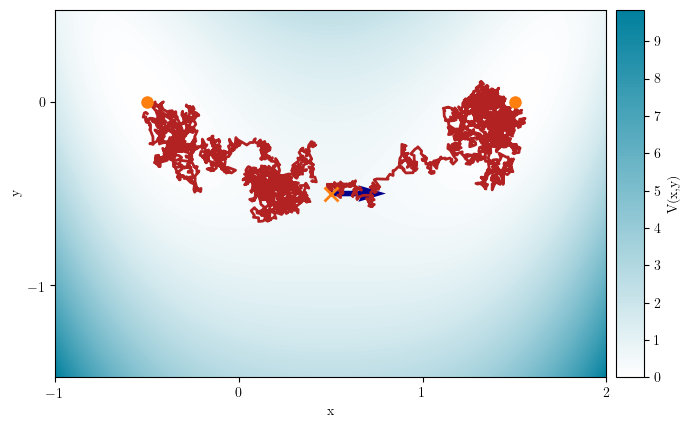

In [414]:
drift_func = double_well_drift_curved
potential = potential_curved
_ = simulate_and_plot_shifted(
    drift_func, potential, simulate_euler_maruyama, x_shift=x_shift, y_shift=y_shift,
    grid_lim_x=1.5, grid_lim_y=1,
    seed=4
)

In [160]:
drift_func = double_well_drift_curved

# Parameters
n_trajs = 2000 
T = 50       
dt = 0.01
dim = 2
D = 0.1
noise_std = D_to_noise_std(D)

# Initialize tracker
eta_e = 0.01  #0.01
gamma = 0.9995  #0.9995
tracking_method = "ema"
if tracking_method == "offline":
    tracker = OfflineVARTracker(dim, eta_e=eta_e)
elif tracking_method == "ema":
    tracker = ExponentialCovarianceTracker(dim, gamma=gamma, eta_e=eta_e, store_history=True)
elif tracking_method == "online":
    eta_M = 0.0005
    eta_w = 0.0005
    eta_mean = 0.001
    tracker = OnlineCovarianceTracker(dim, eta_mean=eta_mean, eta_M=eta_M, eta_w=eta_w, eta_e=eta_e, eta_v=.99, n_iter_lu=1, store_history=True)
else: 
    raise ValueError("tracking_method must be 'offline' or 'online'")

seed = 0
all_X_uncontrolled = tracker.train(
    drift_func=drift_func, n_trajs=n_trajs,
    T=T, dt=dt,
    D=D, seed=seed,
    x_shift=x_shift, y_shift=y_shift),
    # n_traj_cov=250)
X = all_X_uncontrolled[-1][0]


c:\Users\abel_\anaconda3\envs\CIT_\lib\site-packages\scipy\linalg\_matfuncs.py:204: LogmExactlySingularWarning: The logm input matrix is exactly singular.
  F = scipy.linalg._matfuncs_inv_ssq._logm(A)


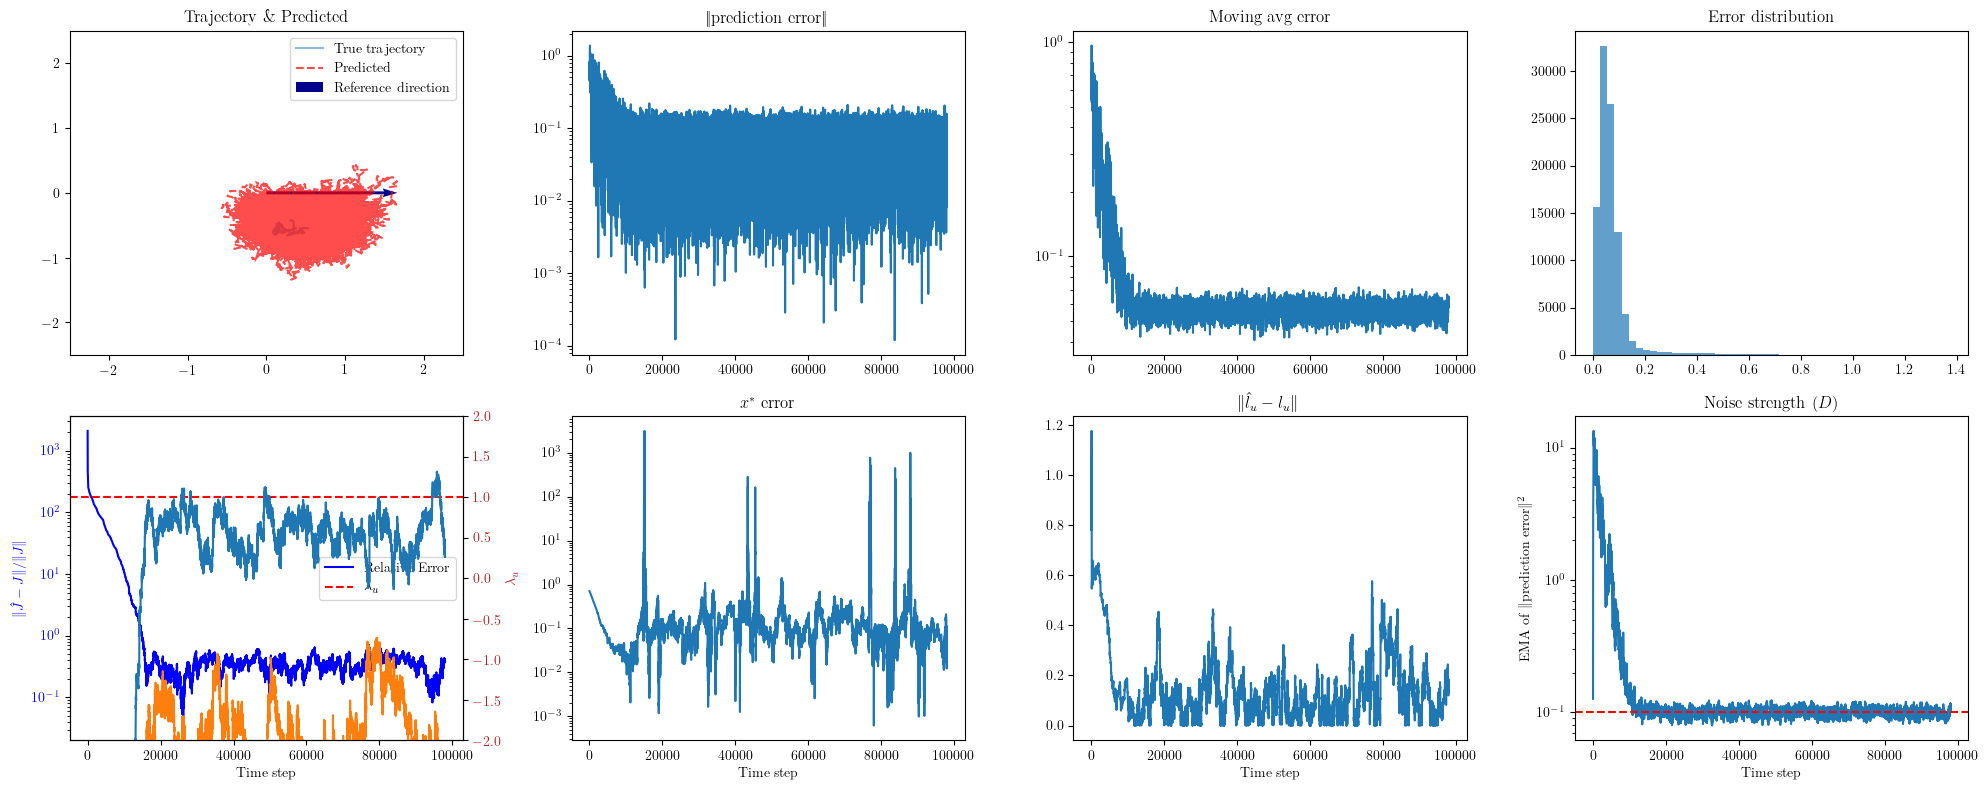

In [161]:
every_t = 1
tracker.pred_history = np.array(tracker.pred_history)[::every_t]
tracker.b_history = np.array(tracker.b_history)[::every_t]
tracker.lu_history = np.array(tracker.lu_history)[::every_t]
tracker.noise_history = np.array(tracker.noise_history)[::every_t]
tracker.A_history = np.array(tracker.A_history)[::every_t]
tracker.lambda_history = np.array(tracker.lambda_history)[::every_t]
tracker.pred_error_history = np.array(tracker.pred_error_history)[::every_t]

plt.figure(figsize=(20,8))

# 1. Phase portrait with predictions vs true
plt.subplot(2,4,1)
plt.plot(X[:,0], X[:,1], alpha=0.5, label="True trajectory")
plt.plot(tracker.pred_history[:,0], tracker.pred_history[:,1], 'r--', alpha=0.7, label="Predicted")
plt.quiver(0, 0, 1, 0, color='darkblue', scale=3, label="Reference direction")
plt.legend(); plt.title("Trajectory \& Predicted")
plt.xlim([-2.5,2.5])
plt.ylim([-2.5,2.5])

# 2. Prediction error norm
plt.subplot(2,4,2)
plt.plot(tracker.pred_error_history)
plt.yscale("log")
plt.title("‖prediction error‖")

# 3. Moving average error
plt.subplot(2,4,3)
window = 50
mov_avg = np.convolve(tracker.pred_error_history, np.ones(window)/window, mode='valid')
plt.plot(mov_avg)
plt.yscale("log")
plt.title("Moving avg error")

# 4. Error histogram
plt.subplot(2,4,4)
plt.hist(tracker.pred_error_history, bins=50, alpha=0.7)
plt.title("Error distribution")

# 5. Relative error in continuous-time linearization
plt.subplot(2,4,5)
from scipy.linalg import logm

x_star_hats = []
for A_disc, b_hat in zip(tracker.A_history, tracker.b_history):
    #A_hat = logm(A_disc) / dt
    x_star_hat = np.linalg.solve(np.eye(A_disc.shape[0]) - A_disc, b_hat)
    x_star_hats.append(x_star_hat)
x_star_hats = np.array(x_star_hats)

rel_error = np.array([
    np.linalg.norm(logm(A)/dt - A_linearized, 'fro') / np.linalg.norm(A_linearized, 'fro')
    for A in tracker.A_history
])

lambdas = np.array([np.linalg.eigvals(logm(A)/dt) for A in tracker.A_history])
fig = plt.gcf()  # get current figure
ax1 = plt.gca()  # get current axis (subplot 5)

# Plot relative error
ax1.plot(rel_error, color='blue', label="Relative Error")
ax1.set_yscale("log")
#ax1.set_title(r"$\|\hat{A} - A\| / \|A\|$")
ax1.set_xlabel("Time step")
ax1.set_ylabel("$\|\hat{J} - J\| / \|J\|$", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_xlabel("Time step")

# Plot lambda on second y-axis
ax2 = ax1.twinx()
ax2.axhline(lambda_u_rescaling, color='red', linestyle='--', label=r"$\lambda_u$")
#ax2.plot(np.log(tracker.lambda_history)/dt, color='firebrick', linestyle='--', label=r"$\hat{\lambda}_u$")
ax2.plot(lambdas)
ax2.set_ylabel("$\lambda_u$", color='firebrick')
ax2.tick_params(axis='y', labelcolor='firebrick')
ax2.set_ylim([-2,2])

# Optional: add combined legend
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc='right')


# location / error of fixed point / b
plt.subplot(2,4,6)
#plt.plot(x_star_hats[:,0], x_star_hats[:,1])
#plt.plot(x_star[0], x_star[1], 'rx', markersize=10, label="True fixed point")
# 
plt.plot(np.linalg.norm(x_star_hats-x_star, axis=1))

tracker.b_history = np.array(tracker.b_history)
#plt.title("$b$ location")
#plt.plot(tracker.b_history[:,0], tracker.b_history[:,1])
#plt.plot(b_true[0], b_true[1], 'rx', markersize=10, label="True $b$")
plt.title("$x^*$ error")
#plt.plot(np.linalg.norm(tracker.b_history-b_true, axis=1))

#plt.xlim([-1.5, 1.5])
#plt.ylim([-1.5, 1.5])
plt.yscale("log")
plt.xlabel("Time step")

plt.subplot(2,4,7)
errors = [np.min([np.linalg.norm(l - l_true),np.linalg.norm(l + l_true)]) for l in tracker.lu_history]
plt.plot(errors)
plt.xlabel("Time step")
plt.title("$\|\hat{l}_u - l_u\|$") #min of both norms

plt.subplot(2,4,8)
D_history = noise_strength_to_D(tracker.noise_history, dim=2, dt=dt)
plt.plot(D_history) #tracker.noise_history)
true_noise_strength = dim * noise_std**2  * dt  
plt.axhline(D, color='r', linestyle='--', label="True noise strength")
plt.yscale("log")
plt.title("Noise strength ($D$)")
plt.xlabel("Time step")
plt.ylabel("EMA of $\|$prediction error$\|^2$")

plt.tight_layout()
if tracking_method == "ema":
    plt.savefig(f"figures/estimation_results_D{D}_ntraj{n_trajs}_T{T}_{tracking_method}_etae{eta_e}_rs{seed}.pdf", dpi=300)
elif tracking_method == "online":
    plt.savefig(f"figures/estimation_results_D{D}_ntraj{n_trajs}_T{T}_{tracking_method}_etam{eta_M}_etaw{eta_w}_etamean{eta_mean}_etae{eta_e}_rs{seed}.pdf", dpi=300)
plt.show()

In [163]:
x_star_hats[-1], x_star

(array([ 0.46999598, -0.4974034 ]), array([ 0.5, -0.5]))

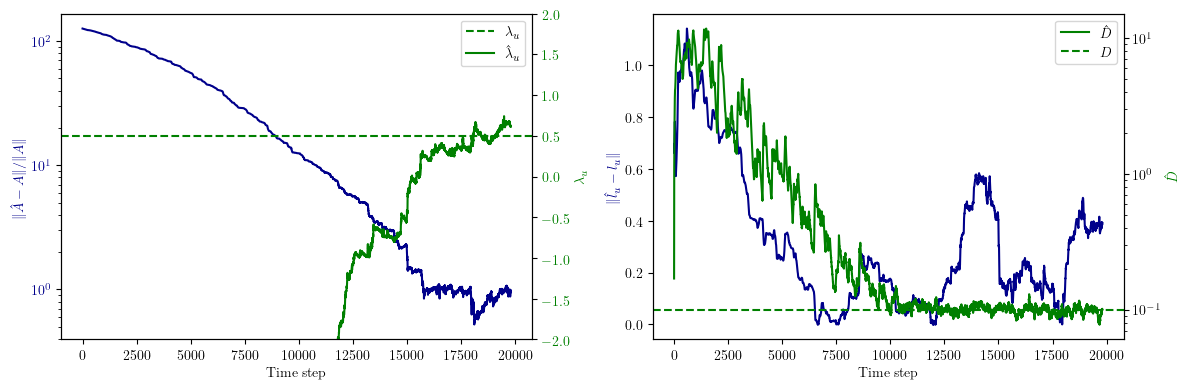

In [97]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
rel_error = np.array([
    np.linalg.norm((A - np.eye(2))/dt - A_linearized, 'fro') / np.linalg.norm(A_linearized, 'fro')
    for A in tracker.A_history
])
fig = plt.gcf()  # get current figure
ax1 = plt.gca()  

# Plot relative error
ax1.plot(rel_error, color='darkblue')
ax1.set_yscale("log")
#ax1.set_title(r"$\|\hat{A} - A\| / \|A\|$")
ax1.set_xlabel("Time step")
ax1.set_ylabel("$\|\hat{A} - A\| / \|A\|$", color='darkblue')
ax1.tick_params(axis='y', labelcolor='darkblue')
ax1.set_xlabel("Time step")

# Plot lambda on second y-axis
ax2 = ax1.twinx()
ax2.axhline(lambda_u_rescaling, color='green', linestyle='--', label="$\lambda_u$")
ax2.plot(np.log(tracker.lambda_history)/dt, color='green', linestyle='-', label=r"$\hat{\lambda}_u$")
ax2.set_ylabel("$\lambda_u$", color='green')
ax2.tick_params(axis='y', labelcolor='green')
ax2.set_ylim([-2,2])

# Optional: add combined legend
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc='upper right')


plt.subplot(1,2,2)
fig = plt.gcf()  # get current figure
ax1 = plt.gca()  
errors = [np.min([np.linalg.norm(l - l_true),np.linalg.norm(l + l_true)]) for l in tracker.lu_history]
ax1.plot(errors, 'darkblue')
ax1.set_xlabel("Time step")
ax1.set_ylabel("$\|\hat{l}_u - l_u\|$", color='darkblue') #min of both norms
#ax1.set_title("$\|\hat{l}_u - l_u\|$") #min of both norms

ax2 = ax1.twinx()
D_history = noise_strength_to_D(tracker.noise_history, dim=2, dt=dt)
ax2.plot(D_history, 'green', label="$\hat{D}$") #tracker.noise_history)
true_noise_strength = dim * noise_std**2  * dt
ax2.axhline(D, color='green', linestyle='--', label="$D$")
ax2.set_yscale("log")
#ax2.set_title("Noise strength ($D$)")
ax2.set_xlabel("Time step")
ax2.set_ylabel("$\hat{D}$", color='green')
ax2.legend()

plt.tight_layout()
plt.savefig(f"figures/estimation_errors_D{D}_ntraj{n_trajs}_T{T}_{tracking_method}_etae{eta_e}_rs{seed}.pdf", dpi=300)
plt.show()

In [796]:
# A_est = (tracker.A_history[-1] - np.eye(2)) / dt

# print("Linearized dynamics at saddle:\n", A_linearized)
# print("Inferred linear map (last step):\n", A_est)
# Lambda_est, Q_mat_est = np.linalg.eig(A_est)
# print("Inferred eigenvalues:", Lambda_est)

In [797]:
X_prev = []
X_next = []
for X in all_X_uncontrolled:
    X_prev.append(X[:-1])
    X_next.append(X[1:])

X_prev = np.vstack(X_prev)  # shape (N_total_steps, dim)
X_next = np.vstack(X_next)

# Solve for continuous-time Jacobian A such that X_next - X_prev ≈ A @ X_prev * dt
A_est, _, _, _ = np.linalg.lstsq(X_prev * dt, (X_next - X_prev), rcond=None)

Lambda_est, Q_mat_est = np.linalg.eig(A_est)
print("Stable inferred A:\n", A_est)
print("Eigenvalues:", Lambda_est)

print("${{\hat{{\\lambda}}}}$ = {:.4f}".format(tracker.lambda_history[-1]))
D_est = noise_strength_to_D(tracker.noise_strength, dt, dim=dim, sde_convention="sqrt2D")
print(f"$\\hat{{D}}$ = {D_est:.4f}")

Stable inferred A:
 [[ 0.3279624  -0.62772634]
 [ 0.26881681 -0.93877381]]
Eigenvalues: [ 0.17668534 -0.78749674]
${\hat{\lambda}}$ = 1.0045
$\hat{D}$ = 0.1075


## Control

In [164]:
# difference between quad, erf and arb.prec. committor control
# no difference for D=0.1
a = .5
noise_strength = tracker.noise_strength 
D_est = noise_strength_to_D(noise_strength, dt, dim)
print("Estimated D from noise strength:", D_est)
D_true = D
print("True D:", D_true)
r = tracker.lambda_history[-1] / (2*D)

offset = np.dot(x_star_hats[-1] - x_star, tracker.lu_history[-1])  # project error onto estimated unstable direction

u_vals = np.linspace(-a, a, 500)

# Committor function using erf
sqrt_r2 = np.sqrt(r/2)
q_vals = (erf(sqrt_r2 * u_vals) - erf(-sqrt_r2 * a)) / (erf(sqrt_r2 * a) - erf(-sqrt_r2 * a))
# q'(u) using analytic derivative
q_prime = np.sqrt(2*r/np.pi) * np.exp(-0.5 * r * u_vals**2) / (erf(sqrt_r2 * a) - erf(-sqrt_r2 * a))
# Committor control u* = 2 D q'/q
u_star_erf_2 = 4 * D * q_prime / np.maximum(q_vals, 1e-12)  # avoid division by zero

u_star_erf = committor_control_erf(u_vals-offset, lambda_u=tracker.lambda_history[-1], D=D, a=a)

#u_star_quad = committor_control_quad_1d(u_vals, a=a, lambda_u=tracker.lambda_history[-1], D=D)

dps = 200
#u_star_hp = high_precision_control(u_vals, a=a, r=r, D=D, precision=dps)

u_relu = -relu_control_1d(-u_vals, lambda_u=tracker.lambda_history[-1])

Estimated D from noise strength: 0.10861479234661854
True D: 0.1


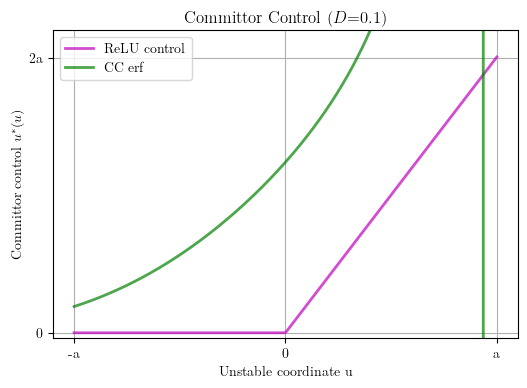

In [165]:
# Plot
plt.figure(figsize=(6,4))
plt.plot(-u_vals, u_relu, 'm', lw=2, label='ReLU control', alpha=0.7)
#plt.plot(-u_vals, u_star_hp, '--', color='b', lw=2, label=f'Committor control (dps {dps})', alpha=0.7) #decimal places of significant digits
plt.plot(-u_vals, u_star_erf, 'g', lw=2, label='CC erf', alpha=0.7)
#plt.plot(u_vals, u_star_erf_2, 'r--', lw=1, label='CC erf 2', alpha=0.7)
#plt.plot(-u_vals, u_star_quad, ':', color='purple', lw=1, label='CC quad', alpha=1)

#plt.axhline(0, color='k', lw=0.8)
#plt.axvline(-a, color='r', ls='--', label='Absorbing A')
#plt.axvline(a, color='g', ls='--', label='Absorbing B')
plt.ylim([-0.02, 2*a + 0.1])
plt.xticks([-a, 0, a], ['-a', '0', 'a'])
plt.yticks([0, 2*a], ['0', '2a'])
plt.xlabel("Unstable coordinate u")
plt.ylabel("Committor control $u^*(u)$")
plt.title(f"Committor Control ($D$={D})")
plt.legend()
plt.grid(True)
plt.show()

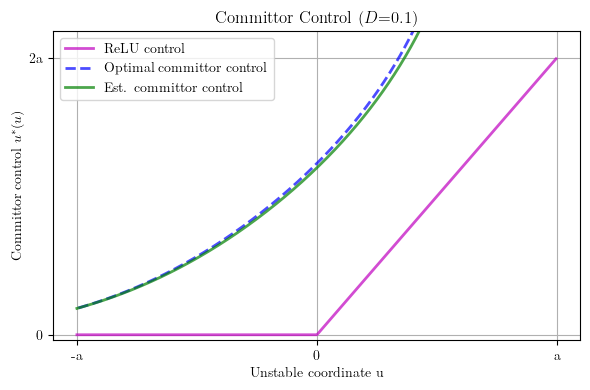

In [178]:
u_star_erf_est = np.array([committor_control_erf_scalar(u_v, lambda_u=tracker.lambda_history[-1], D=D_est, a=.5) for u_v in u_vals])

plt.figure(figsize=(6,4))
plt.plot(-u_vals[1:], u_relu[1:], 'm', lw=2, label='ReLU control', alpha=0.7)
plt.plot(-u_vals[105:], u_star_erf[105:], '--', color='b', lw=2, label=f'Optimal committor control', alpha=0.7) 
plt.plot(-u_vals[1:], u_star_erf_est[1:], 'g', lw=2, label=f'Est. committor control', alpha=0.7) 
plt.ylim([-0.02, 2*a + 0.1])
plt.xticks([-a, 0, a], ['-a', '0', 'a'])
plt.yticks([0, 2*a], ['0', '2a'])
plt.xlabel("Unstable coordinate u")
plt.ylabel("Committor control $u^*(u)$")
plt.title(f"Committor Control ($D$={D})")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(f"figures/committor_control_comparison_D{D}_ntraj{n_trajs}_T{T}_{tracking_method}_etae{eta_e}_rs{seed}.pdf", dpi=300)
plt.show()  

In [193]:
import numpy as np

# -----------------------
# Simulation parameters
# -----------------------
n_traj = 1
dt = 0.01
T = 1000
noise_std = 0.1
seed = 1
dim = 2
init_range = 0.5
x_max = 0.5
oob_coords = [0]  # list of coordinates to monitor
abort_on_exit = True

# -----------------------
# Controllers to run
# -----------------------
controllers_to_run = {
    "Autonomous": None,
    "Optimal": erf_feedback,
    "Committor": erf_feedback,
    "Committor (est. FP)": erf_feedback,
    "ReLU": relu_feedback
}

# -----------------------
# True parameters
# -----------------------
l_unstable_true = np.array([1, 0])
lambda_u_true = .5
D_true = D  # make sure D is defined
x_fp_true = x_star

# -----------------------
# Estimated parameters
# -----------------------
l_unstable_est = tracker.lu_history[-1]
# Ensure the unstable vector points left along x[0]
if l_unstable_est[0] < 0:
    l_unstable_est = -l_unstable_est

lambda_est = tracker.lambda_history[-1]
D_est = noise_strength_to_D(tracker.noise_history[-1], dt, dim=dim, sde_convention="sqrt2D")
b_est = tracker.b_history[-1]
x_fp_est = x_star_hats[-1]
print(lambda_u_true, lambda_est)
print(D_true, D_est)

# -----------------------
# Run simulations
# -----------------------
all_results = run_simulations(
    T=T,
    dim=dim,
    dt=dt,
    n_traj=n_traj,
    drift_func=drift_func,
    noise_std=noise_std,
    init_range=init_range,
    a=0.5,
    l_unstable_true=l_unstable_true,
    lambda_u_true=lambda_u_true,
    D_true=D_true,
    x_fp_true=x_fp_true,
    l_unstable_est=l_unstable_est,
    lambda_est=lambda_est,
    D_est=D_est,
    x_fp_est=x_fp_est,
    controllers_to_run=controllers_to_run,
    x_max=x_max,
    oob_coords=oob_coords,
    abort_on_exit=abort_on_exit,
    control_r_neigh=0.5,
    control_nbhd_shape="rectangular",
    seed=seed
)


0.5 1.0026894200805618
0.1 0.10861479234661854


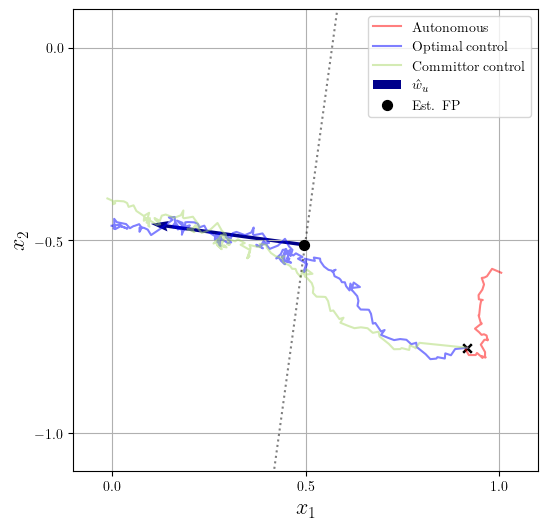

In [196]:
# Access trajectories like before:
all_X_uncontrolled = all_results["Autonomous"]
all_X_opt_ctrld = all_results["Optimal"]
all_X_relu_ctrld = all_results["ReLU"]
all_X_comm_ctrld = all_results["Committor"]
all_X_comm_ctrld_fp = all_results["Committor (est. FP)"]

trajectories_info = {
    "Autonomous": (all_X_uncontrolled, "red"),
    "Optimal control": (all_X_opt_ctrld, "blue"),
    #"ReLU control": (all_X_relu_ctrld, "orange"),
    #"Committor control": (all_X_comm_ctrld, "#007f2f"),
    "Committor control": (all_X_comm_ctrld_fp, "#aad96a")
}

fig, ax = plt.subplots(figsize=(6,6))
plot_trajectories(ax, trajectories_info, tracker, x_fp_true=x_fp_true, show_n=5, title=None)
fig.savefig(f"figures/singletraj_comparison_rs{seed}.pdf", bbox_inches='tight')  
fig.savefig(f"figures/singletraj_comparison_rs{seed}.png", dpi=300, bbox_inches='tight')  
plt.show()


### Deterministic 

In [38]:
# n_traj = 1
# dt = 0.01
# T  = 1000
# noise_std = 0.
# seed = 0
# controllers_to_run = {
#     "Autonomous": None,
#     "ReLU": relu_feedback
# }

# lambda_u_real = 1
# D_real = D
# all_results = run_simulations(T, dim, dt, n_traj, drift_func, noise_std,
#                               l_unstable_real=np.array([1, 0]), lambda_u_real=lambda_u_real, D_real=D_real,
#                              tracker=tracker, controllers_to_run=controllers_to_run, seed=0)

# # Access trajectories like before:
# all_X_uncontrolled = all_results["Autonomous"]
# all_X_relu_ctrld = all_results["ReLU"]


# trajectories_info = {
#     "Autonomous": (all_X_uncontrolled, "red"),
#     "ReLU control": (all_X_relu_ctrld, "orange"),
# }

# fig, ax = plt.subplots(figsize=(6,6))
# plot_trajectories(ax, trajectories_info, tracker, show_n=5, title=None) 
# #fig.savefig(f"figures/singletraj_comparison_rs{seed}.pdf", bbox_inches='tight')  
# #fig.savefig(f"figures/singletraj_comparison_rs{seed}.png", dpi=300, bbox_inches='tight')  
# plt.show()


### Success rate (init in right half, check % moved to left committor bound) + control cost

In [ ]:
# -----------------------
# Simulation parameters
# -----------------------
n_traj = 1
dt = 0.01
T = 1000
noise_std = 0.1
seed = 0
dim = 2
init_range = 0.5
x_max = 0.5
oob_coords = [0]  # coordinates to monitor
abort_on_exit = True

# -----------------------
# True parameters
# -----------------------
l_unstable_true = np.array([1, 0])
lambda_u_true = lambda_u_rescaling
D_true = D  # make sure D is defined

# -----------------------
# Estimated parameters
# -----------------------
l_unstable_est = tracker.lu_history[-1]
# Ensure the unstable vector points left along x[0]
if l_unstable_est[0] < 0:
    l_unstable_est = -l_unstable_est

lambda_est = tracker.lambda_history[-1]
D_est = noise_strength_to_D(tracker.noise_history[-1], dt, dim=dim, sde_convention="sqrt2D")
b_est = tracker.b_history[-1]
x_fp_est = x_star_hats[-1]

print("True λ:", lambda_u_true, "Estimated λ:", lambda_est)
print("True D:", D_true, "Estimated D:", D_est)

# -----------------------
# Run simulations
# -----------------------
results = run_simulations_hit_sides(
    T=T,
    dim=dim,
    dt=dt,
    drift_func=drift_func,
    noise_std=noise_std,
    a=0.5,
    l_unstable_true=l_unstable_true,
    lambda_u_true=lambda_u_true,
    D_true=D_true,
    x_fp_true=x_fp_true,
    l_unstable_est=l_unstable_est,
    lambda_est=lambda_est,
    D_est=D_est,
    x_fp_est=x_fp_est,
    controllers_to_run={
        #"Optimal": erf_feedback,
        "Committor (est. FP)": erf_feedback
    },
    n_grid=10,
    x_max=x_max,
    grid_side="positive",
    oob_coords=oob_coords,
    control_r_neigh=0.5,
    control_nbhd_shape="rectangular",
    seed=seed
)

for label, data in results.items():
    prop = data["hit_proportion"]
    mean_sq_ctrl = data["overall_mean_squared_control"]
    print(f"{label}:")
    print(f"  Positive side hit: {prop['positive']*100:.1f}%")
    print(f"  Negative side hit: {prop['negative']*100:.1f}%")
    print(f"  None hit: {prop['none']*100:.1f}%")
    print(f"  Mean squared control cost <|u_t|^2>: {mean_sq_ctrl:.4f}")



True λ: 0.5 Estimated λ: 1.0062704053648652
True D: 0.1 Estimated D: 0.10058020429075368
Committor (est. FP):
  Positive side hit: 30.0%
  Negative side hit: 70.0%
  None hit: 0.0%
  Mean squared control cost <|u_t|^2>: 1.6413


### Across time

In [ ]:
time_points, results_over_time = evaluate_control_over_time(
    tracker, drift_func, D_true=D, lambda_u_true=lambda_u_rescaling, x_fp_true=x_star, l_unstable_true=l_unstable_true, a=0.5,
    T=1000, dt=0.01, dim=2, n_grid=5, x_max=0.5,
    oob_coords=[0], control_r_neigh=0.5, control_nbhd_shape="rectangular",
    seed=0, eval_interval=100
)


KeyboardInterrupt: 

In [ ]:
time_points_r = time_points[:len(time_points)]

# Extract labels
labels = list(results_over_time[time_points[0]].keys())

# Prepare hit proportion and control cost data
hit_neg = {label: [] for label in labels}
mean_sq_ctrl = {label: [] for label in labels}

for t in time_points_r:
    for label in labels:
        prop = results_over_time[t][label]["hit_proportion"]
        hit_neg[label].append(prop["negative"])
        mean_sq_ctrl[label].append(results_over_time[t][label]["overall_mean_squared_control"])

# Define color maps
hit_colors = ['firebrick', 'lightcoral']  # hit proportions
ctrl_colors = ['darkblue', 'lightblue']   # control costs
markers = ['o', '.']

# Create figure and first axis for hit proportions
fig, ax1 = plt.subplots(figsize=(10, 5))

label = labels[0]
ax1.plot(time_points_r, hit_neg[label], color=hit_colors[0], linewidth=5)
label = labels[1]
ax1.plot(time_points_r, hit_neg[label], color=hit_colors[1])

ax1.set_xlabel("Time step")
ax1.set_ylabel("Hit proportion ($x_0=-0.5$)", color='firebrick')
ax1.set_ylim(0, 1)
ax1.tick_params(axis='y', labelcolor='firebrick')
ax1.grid(True)

# Create second axis for control cost
ax2 = ax1.twinx()
ax2.set_yscale('log')
label = labels[0]
ax2.plot(time_points_r, mean_sq_ctrl[label], color=ctrl_colors[0])
label = labels[1]
ax2.plot(time_points_r, mean_sq_ctrl[label], marker='.', linestyle='--', color=ctrl_colors[1])

ax2.set_ylabel("Mean Squared Control", color=ctrl_colors[0])
ax2.tick_params(axis='y', labelcolor=ctrl_colors[0])

# Create grouped legend manually
legend_elements = []
for i, label in enumerate(labels):
    # Success rate (hit proportion)
    legend_elements.append(Line2D([0], [0], color=hit_colors[i % len(hit_colors)], linestyle='-', label=f'{label} success rate'))
    # Control cost
    legend_elements.append(Line2D([0], [0], color=ctrl_colors[i % len(ctrl_colors)],  linestyle='-', label=f'{label} control cost'))

ax1.legend(handles=legend_elements, loc='lower right')

#plt.title("Hit Proportion ($x_0=-0.5$) and Control Cost")

#plt.savefig(f"figures/hitprop_controlcost_over_time_D{D}_{tracking_method}.pdf", bbox_inches='tight')
#plt.savefig(f"figures/hitprop_controlcost_over_time_D{D}_{tracking_method}.png", bbox_inches='tight')
plt.show()


NameError: name 'time_points' is not defined

# Empirical committor 

In [197]:
# Define sets A and B (in 2D)
def in_A(x, fp_loc=np.array([-1., 0.0]), radius=0.2):
    return np.linalg.norm(x - fp_loc) < radius

def in_B(x, fp_loc=np.array([1., 0.0]), radius=0.2):
    return np.linalg.norm(x - fp_loc) < radius



def empirical_committor_grid(sim_wrapper, n_traj=200, T=2000, dt=0.01, D=.0,
                             min_x=-0.5, max_x=0.5, num_points=10, seed=0, desc=""):
    """
    Compute empirical committor probability grid for a given simulation wrapper,
    including explicit noise strength D.

    Parameters
    ----------
    sim_wrapper : function
        Function with signature sim_wrapper(x0, T, dt, noise) -> trajectory (T x dim).
    n_traj : int
        Number of independent trajectories per grid point.
    T : int
        Number of timesteps per trajectory.
    dt : float
        Timestep size.
    D : float
        Noise strength (diffusion coefficient) to scale the stochastic term.
    min_x, max_x : float
        Grid boundaries.
    num_points : int
        Number of points along each dimension.
    desc : str
        Description for tqdm.

    Returns
    -------
    grid : np.ndarray
        1D grid points.
    q_grid : np.ndarray
        Empirical committor probabilities (num_points x num_points).
    """
    np.random.seed(seed)
    grid = np.linspace(min_x, max_x, num_points)
    q_grid = np.zeros((num_points, num_points))

    print(f"Calculating empirical committor for {desc}")
    for i, x1 in enumerate(tqdm(grid, desc="x1 grid")):
        for j, x2 in enumerate(grid):
            x0 = np.array([x1, x2])
            successes = 0

            # Pre-generate noise scaled by D
            noises = np.random.randn(n_traj, T, x0.size) * np.sqrt(2 * D * dt)

            for k in range(n_traj):
                X = sim_wrapper(x0.copy(), T, dt, noise=noises[k])

                # Early stopping when hitting A or B
                for t in range(T):
                    if in_A(X[t]):
                        break
                    if in_B(X[t]):
                        successes += 1
                        break

            q_grid[j, i] = successes / n_traj

    return grid, q_grid


def generic_simulation(x0, T, dt, control_func=None, noise=None):
    """
    Generic trajectory simulator including noise strength D in pre-generated noise.

    Parameters
    ----------
    x0 : np.ndarray
        Initial state.
    T : int
        Number of timesteps.
    dt : float
        Timestep size.
    control_func : callable or None
        Function control_func(x) -> u_t.
    noise : np.ndarray or None
        Pre-generated noise of shape (T, dim). If None, generate randomly.

    Returns
    -------
    X : np.ndarray
        Trajectory of shape (T, dim).
    """
    dim = x0.size
    X = np.zeros((T, dim))
    X[0] = x0

    if noise is None:
        raise ValueError("Noise array must be provided for scaled diffusion.")

    for t in range(1, T):
        dx = drift_func(t, X[t-1])
        u_t = control_func(X[t-1]) if control_func is not None else np.zeros(dim)
        X[t] = X[t-1] + dx*dt + u_t*dt + noise[t]

    return X


In [68]:
lambda_est = tracker.lambda_history[-1]
l_unstable_est = tracker.lu_history[-1]
if l_unstable_est[0] < 0:
    l_unstable_est = -l_unstable_est
noise_strength = tracker.noise_strength 
D_est = noise_strength_to_D(noise_strength, dt, dim)
b_est = tracker.b_history[-1]

sim_uncontrolled = partial(generic_simulation, control_func=None)
sim_relu = partial(generic_simulation, control_func=partial(relu_feedback, l_unstable=l_unstable_est, lambda_u=lambda_est, D=D_est, x_fp=b_est, r_neigh=0.5))
sim_committor = partial(generic_simulation, control_func=partial(erf_feedback, a=0.5, l_unstable=l_unstable_est, lambda_u=lambda_est, D=D_est, x_fp=b_est, r_neigh=0.5)) #rectangular
sim_relu_opt = partial(generic_simulation, control_func=partial(relu_feedback, l_unstable=l_unstable_true, lambda_u=1., D=D, x_fp=np.array([0.,0.]), r_neigh=0.5))


In [69]:
n_traj = 200
grid, q_uncontrolled = empirical_committor_grid(sim_uncontrolled, D=D, n_traj=n_traj, T=2000, dt=0.01, num_points=10, desc="Autonomous")
_, q_relu = empirical_committor_grid(sim_relu, D=D, n_traj=n_traj, T=2000, dt=0.01, num_points=10, desc="ReLU control")
_, q_comm = empirical_committor_grid(sim_committor, D=D, n_traj=n_traj, T=2000, dt=0.01, num_points=10, desc="Committor control")
_, q_relu_opt = empirical_committor_grid(sim_relu_opt, D=D, n_traj=n_traj, T=2000, dt=0.01, num_points=10, desc="ReLU control")

Calculating empirical committor for Autonomous


x1 grid: 100%|██████████| 10/10 [06:50<00:00, 41.00s/it]


Calculating empirical committor for ReLU control


x1 grid: 100%|██████████| 10/10 [11:19<00:00, 68.00s/it]


Calculating empirical committor for Committor control


x1 grid:  20%|██        | 2/10 [03:03<12:12, 91.61s/it]


KeyboardInterrupt: 

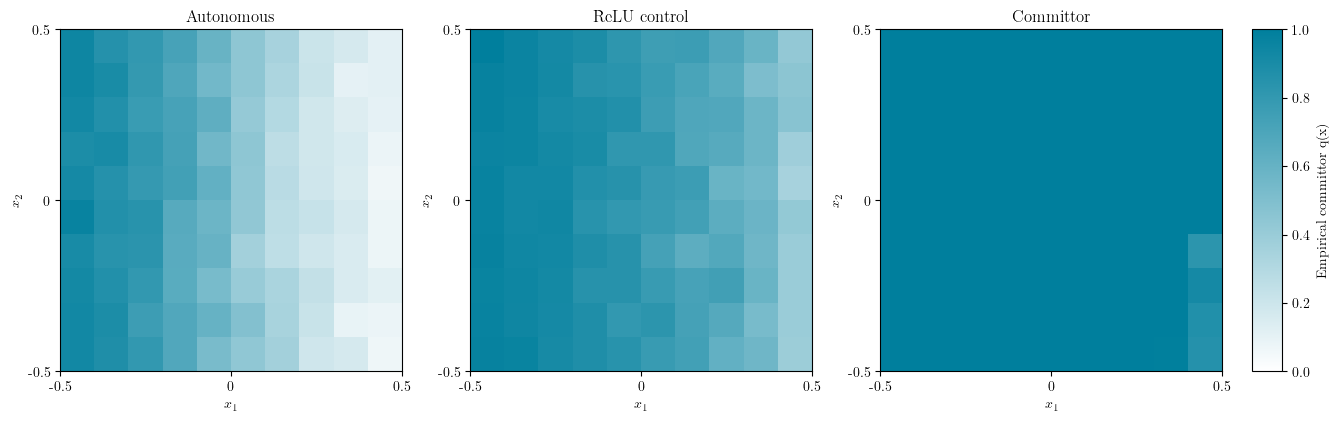

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
ccn_color = "#007f9d"
ccn_cmap = LinearSegmentedColormap.from_list("custom_007f9d", ["#ffffff", ccn_color])


# Plot results
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, q, title in zip(
    axs,
    [q_uncontrolled, q_relu, q_comm],
    ["Autonomous", "ReLU control", "Committor"]
):
    im = ax.imshow(1-q, origin='lower', extent=[-0.5, 0.5, -0.5, 0.5],
                   vmin=0, vmax=1, cmap=ccn_cmap)
    #pc = ax.pcolormesh(X, Y, Z, shading='auto', cmap=ccn_cmap, vmin=0.0, vmax=1.0)

    ax.set_title(title)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")

    ax.set_xticks([-0.5, 0, 0.5])
    ax.set_yticks([-0.5, 0, 0.5])
    ax.set_xticklabels([-0.5, 0, 0.5])
    ax.set_yticklabels([-0.5, 0, 0.5])

# Get the bounding box of the subplots (they all have same y)
pos = axs[0].get_position()

# Place colorbar all the way to the right, matching subplot height
cbar_ax = fig.add_axes([0.92, pos.y0, 0.02, pos.height])
cbar = fig.colorbar(im, cax=cbar_ax, orientation='vertical')
cbar.set_label("Empirical committor q(x)")

# cbar = plt.colorbar(pc, ax=ax, label="Empirical Committor")
# cbar.ax.tick_params(labelsize=fontsize)  # for tick labels
# cbar.set_label("Empirical Committor", fontsize=fontsize)  # for colorbar label

plt.show()


# Multiple runs

In [415]:
n_runs = 10
# Parameters
n_trajs = 200 * 10
T = 50      
dt = 0.01
# dim = 2
D = 0.1
tracker_method = 'ema'

# Initialize tracker
eta_e = 0.01  #0.01
gamma = 0.9995  #0.9995
system = 'curved'
if system == 'curved':
    drift_func = double_well_drift_curved
elif system == 'linear':
    drift_func = double_well_drift_linear
all_trackers_dw = run_training_only(n_runs=n_runs, n_trajs=n_trajs, drift_func=drift_func, dt=dt, D=D, 
                                 tracker_method=tracker_method, T_tracker_trajs=T, gamma=gamma, eta_e=eta_e, x_shift=x_shift, y_shift=y_shift)

Training trackers: 100%|██████████| 10/10 [04:00<00:00, 24.04s/it]


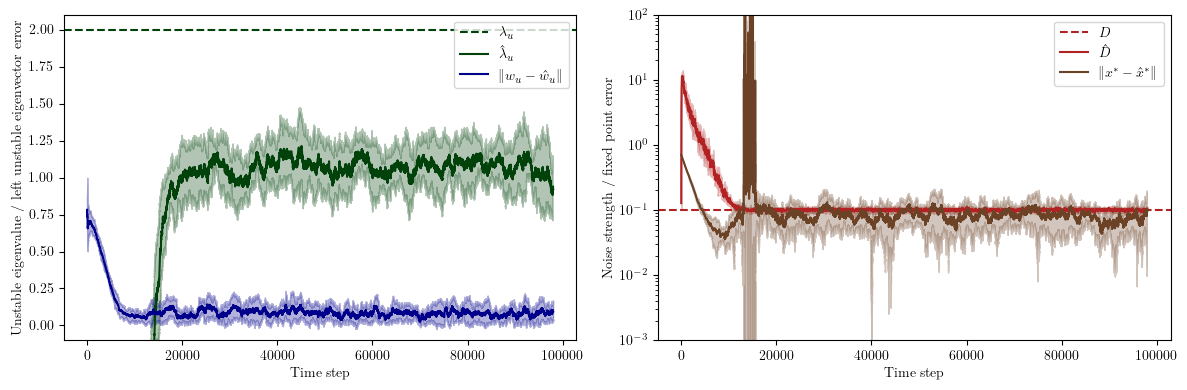

In [418]:
l_true = np.array([1, 0])
x_star = np.array([x_shift, y_shift])

plot_tracker_metrics(all_trackers_dw, A_linearized, l_true, x_star, dt, lambda_u_rescaling, D, system, tracker_method)

In [ ]:
all_results = run_inference_and_evaluation(n_runs, n_trajs, dt, D, drift_func=drift_func, T_tracker_trajs=T, gamma=gamma, eta_e=eta_e, x_shift=x_shift, y_shift=y_shift)

  0%|          | 0/10 [00:00<?, ?it/s]c:\Users\abel_\anaconda3\envs\CIT_\lib\site-packages\scipy\linalg\_matfuncs.py:204: LogmExactlySingularWarning: The logm input matrix is exactly singular.
  F = scipy.linalg._matfuncs_inv_ssq._logm(A)
100%|██████████| 10/10 [34:14<00:00, 205.41s/it]


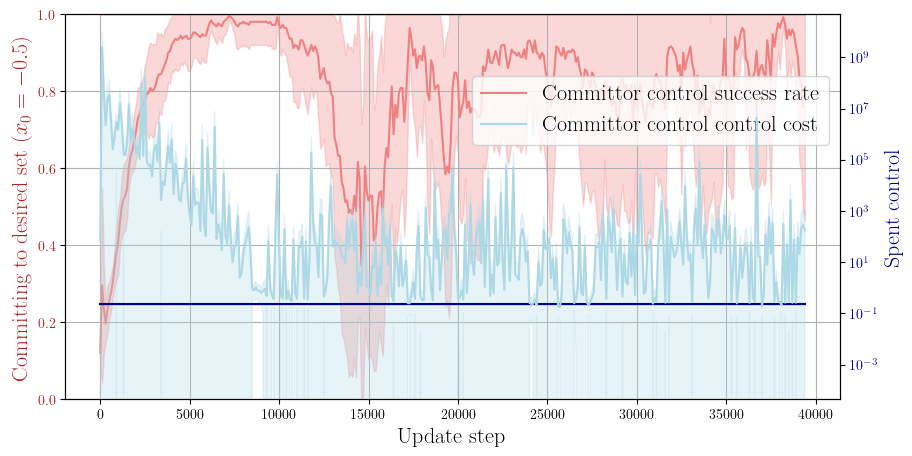

In [ ]:
plot_hit_and_control(all_results, until_t=-1, title=None)


# Pendulum

In [ ]:
def split_wrapped_trajectory(traj_theta, traj_omega):
    """
    Split a trajectory into segments where the angular coordinate θ remains continuous
    in the wrapped interval, i.e. break at jumps > π.
    """
    wrapped_theta = (traj_theta + np.pi) % (2 * np.pi) - np.pi  # Wrap to [-pi, pi]
    segments = []
    current_seg_theta = [wrapped_theta[0]]
    current_seg_omega = [traj_omega[0]]

    for i in range(1, len(wrapped_theta)):
        if np.abs(wrapped_theta[i] - wrapped_theta[i - 1]) > np.pi:
            # Discontinuity detected — start a new segment
            segments.append((np.array(current_seg_theta), np.array(current_seg_omega)))
            current_seg_theta = []
            current_seg_omega = []
        current_seg_theta.append(wrapped_theta[i])
        current_seg_omega.append(traj_omega[i])

    # Append last segment
    if current_seg_theta:
        segments.append((np.array(current_seg_theta), np.array(current_seg_omega)))

    return segments

def split_trajectories(angles, threshold=np.pi/2):
    angles = np.array(angles)
    # Compute difference between consecutive points
    diffs = np.diff(angles)
    
    # Identify indices where jump exceeds threshold
    split_indices = np.where((diffs > threshold) | (diffs < -threshold))[0] + 1
    
    # Split trajectory at these indices
    trajectories = np.split(angles, split_indices)
    
    return trajectories

def plot_traj_as_segments(ax, traj_wrapped, color, label=None, alpha=0.7, linewidth=1.5):
    """Plot traj_wrapped as segments.
    """
    segments = split_wrapped_trajectory(traj_wrapped[:, 0], traj_wrapped[:, 1])

    for i, (seg_theta, seg_omega) in enumerate(segments):
        ax.plot(seg_theta, seg_omega, color=color, label=label if i == 0 else "", alpha=alpha, linewidth=linewidth)


def wrap_around_saddle(theta, saddle=np.pi):
    """
    Wrap angles so that the saddle point is in the middle.
    This maps theta to [saddle - pi, saddle + pi].
    """
    return ((theta - saddle + np.pi) % (2*np.pi)) + saddle - np.pi

def split_wrapped_trajectory(theta, omega, threshold=np.pi/2):
    """
    Split trajectory into segments wherever jump > threshold.
    Returns a list of (seg_theta, seg_omega)
    """
    diffs = np.diff(theta)
    split_indices = np.where((diffs > threshold) | (diffs < -threshold))[0] + 1
    theta_segments = np.split(theta, split_indices)
    omega_segments = np.split(omega, split_indices)
    return list(zip(theta_segments, omega_segments))

def plot_traj_as_segments(ax, traj, color='blue', label=None, alpha=0.7, linewidth=1.5):
    """
    Plot trajectory as segments after wrapping around the saddle.
    traj: Nx2 array [theta, omega]
    """
    theta_wrapped = wrap_around_saddle(traj[:, 0], saddle=np.pi)
    segments = split_wrapped_trajectory(theta_wrapped, traj[:, 1])

    for i, (seg_theta, seg_omega) in enumerate(segments):
        ax.plot(seg_theta, seg_omega, color=color,
                label=label if i==0 else "", alpha=alpha, linewidth=linewidth)

(-3.141592653589793, 3.141592653589793)

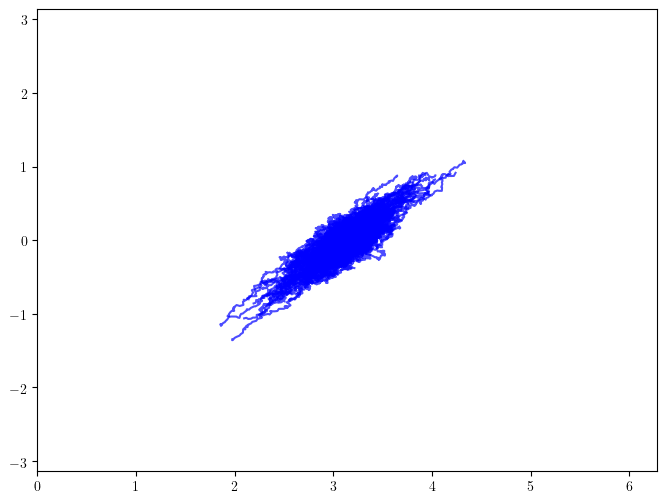

In [343]:
class ControlledPendulum:
    """
    2D damped pendulum with control torque and additive noise:
        dθ/dt = ω
        dω/dt = -b ω - sin(θ) + u(t)
    """

    def __init__(
        self,
        dt: float = 0.05,
        time_span: tuple = (0.0, 10.0),
        damping: float = 0.1,
        noise_std: float = 0.0,
        control_fn=None,
    ):
        self.dt = dt
        self.time_span = time_span
        self.damping = damping
        self.noise_std = noise_std
        self.control_fn = control_fn if control_fn is not None else self.zero_control

    def dynamics(self, x: np.ndarray, t: float) -> np.ndarray:
        """
        Compute dx/dt = f(x, t) with control u(t)
        x[0] = θ, x[1] = ω
        """
        theta, omega = x
        u = self.control_fn(t, x)
        dtheta = omega
        domega = -self.damping * omega - np.sin(theta) + u
        return np.array([dtheta, domega])

    def simulate(self, x0: np.ndarray, random_seed: int = None) -> tuple:
        t_vals = np.arange(self.time_span[0], self.time_span[1], self.dt)
        xs = np.zeros((len(t_vals), 2))
        x = np.array(x0)

        if random_seed is not None:
            rng = np.random.default_rng(random_seed)
            noises = rng.normal(0.0, self.noise_std, size=(len(t_vals), 2)) * np.sqrt(self.dt)
        else:
            noises = self.noise_std * np.random.randn(len(t_vals), 2) * np.sqrt(self.dt)

        for i, t in enumerate(t_vals):
            dx = self.dynamics(x, t)
            x = x + self.dt * dx + noises[i]
            xs[i] = x

        return t_vals, xs
    
def pendulum_drift_ode(t, x):
    dx0 = x[1]
    dx1 = - np.sin(x[0])
    return np.array([dx0, dx1])

# --- Parameters ---
x0 = np.array([np.pi, 0])      # initial [theta, omega]
dt = 0.01
T = 150

# --- Create pendulum instances ---
# 1. Uncontrolled
def zero_control(t, x):
    return 0.0
pend_uncontrolled = ControlledPendulum(dt=dt, time_span=(0.0, T), damping=0., noise_std=0.5, control_fn=zero_control)
# use pendulum_drift_ode to integrate
D = 0.01
noise_std = D_to_noise_std(D)

fig, ax = plt.subplots(figsize=(8,6))
np.random.seed(0)
for i in range(250):
    x0 = np.array([np.pi + 0.1*np.random.randn(), 0.1*np.random.randn()])
    noise =  noise_std * np.random.randn(int(T/dt), 2) * np.sqrt(dt)
    xs_u = simulate_trajectory(x0=x0, T=T, dt=dt, drift_func=pendulum_drift_ode, noise=noise, dim=2)
    plot_traj_as_segments(ax, xs_u, color='blue')
ax.set_xlim(0, 2*np.pi)
ax.set_ylim(-np.pi, np.pi)

In [378]:
drift_func = pendulum_drift_ode
# Parameters
n_trajs = 200 
# T = 50       
# dt = 0.001
dim = 2
D = 0.1
noise_std = D_to_noise_std(D)

tracker = ExponentialCovarianceTracker(dim, gamma=gamma, eta_e=eta_e, store_history=True)

seed = 0
x_shift = np.pi
y_shift = 0.0
all_X_uncontrolled = tracker.train(
    drift_func=pendulum_drift_ode, n_trajs=n_trajs,
    T=T, dt=dt,
    D=D, seed=seed,
    x_shift=x_shift, y_shift=y_shift)
X = all_X_uncontrolled[-1]

l_true = np.array([1.0, 1.0]) / np.linalg.norm(np.array([1.0, 1.0]))
A_linearized = np.array([[0, 1], [1, 0]])
lambda_u_rescaling = 1.0
x_star = np.array([np.pi, 0.0])

In [388]:
n_runs = 100
all_trackers = run_training_only(n_runs=n_runs, n_trajs=n_trajs, drift_func=drift_func, dt=dt, D=D, 
                                 tracker_method=tracker_method, T_tracker_trajs=T, gamma=gamma, eta_e=eta_e, x_shift=x_shift, y_shift=y_shift)

Training trackers: 100%|██████████| 100/100 [1:05:56<00:00, 39.57s/it]


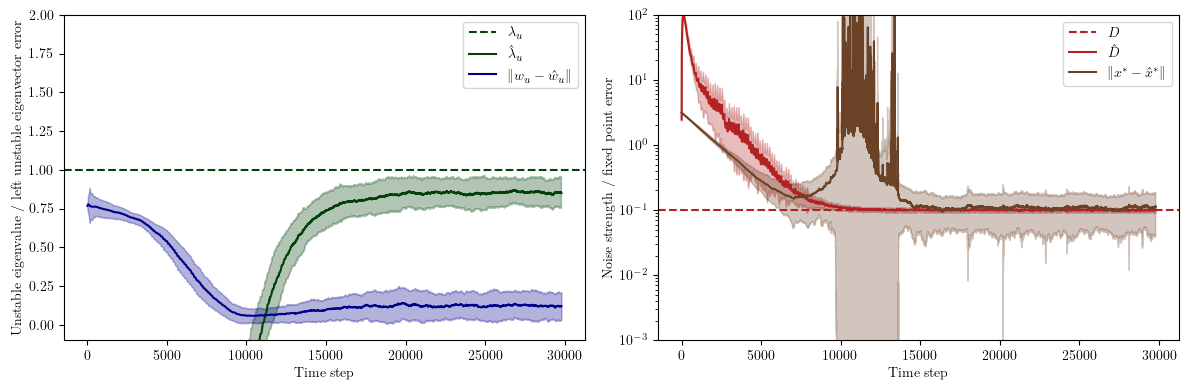

In [ ]:
system = 'pendulum'
plot_tracker_metrics(all_trackers, A_linearized, l_true, x_star, dt, 
                     lambda_u_rescaling, D, system, tracker_method)

In [390]:
all_results = run_inference_and_evaluation(n_runs, n_trajs, dt, D, drift_func=drift_func, T_tracker_trajs=T, gamma=gamma, eta_e=eta_e, x_shift=x_shift, y_shift=y_shift, l_unstable_true=l_true, x_star=x_star)

100%|██████████| 100/100 [2:17:15<00:00, 82.35s/it]


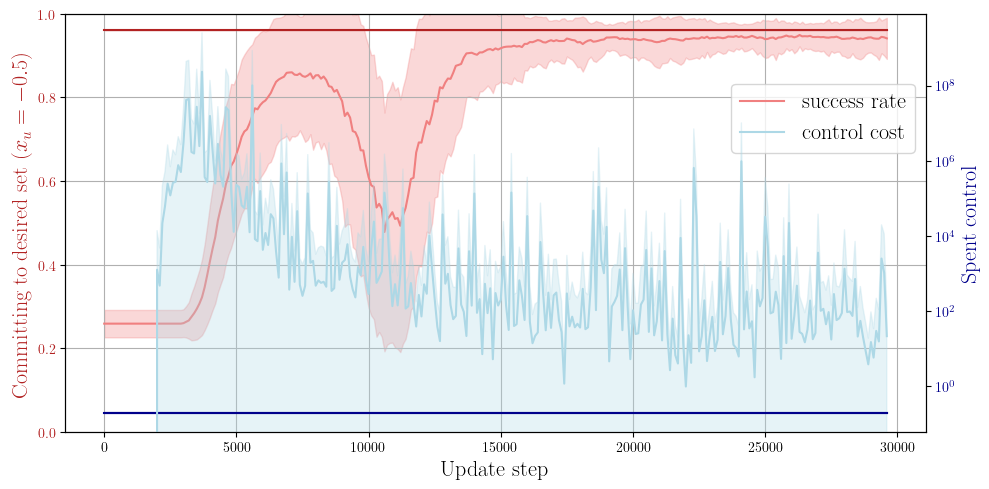

In [393]:
plot_hit_and_control(all_results, until_t=-1, system='pendulum', D=D, n_runs=n_runs)